# Proyecto de Aula — Segundo Corte y actualización del Tercer Corte
## Predicción de Diabetes Mediante Técnicas de Minería de Datos Aplicadas a Indicadores Clínicos y Demográficos

**Integrante:** Isaac Mendoza Herrera
**Programa:** Ingeniería de Sistemas — Universidad de la Costa (CUC)
**Asignatura:** Minería de Datos — Prof. José Escorcia-Gutierrez, Ph.D.
**Tipo de proyecto:** Clasificación (aprendizaje supervisado, binaria)

> **Actualización del tercer corte (Actividad 1):** se agregó la **sección 10**, con la revisión de calidad del modelado, la optimización del modelo y el guardado del pipeline final que usa la aplicación en Streamlit (*GlucoLens*). Las secciones 1 a 9 se conservan como se entregaron en el segundo avance.

Este notebook continúa el trabajo del primer avance. Conserva la carga de datos, la descripción del dataset y el diagnóstico de calidad, corrige la estrategia de limpieza y agrega el análisis exploratorio de datos (EDA), el entrenamiento y la evaluación de modelos de clasificación.

### 1.1 Pregunta de investigación

**¿Es posible predecir si una paciente presenta diabetes (`Outcome = 1`) a partir de ocho indicadores clínicos y demográficos, y cuál de los modelos evaluados —regresión logística, árbol de decisión o random forest— identifica mejor los casos positivos sin generar un número excesivo de falsas alarmas?**

En este problema el error más costoso es el **falso negativo** (una paciente con diabetes clasificada como sana), porque retrasaría la detección. Por eso la comparación de modelos no se basa solo en el *accuracy*: se da prioridad al **recall de la clase 1**, balanceado con la precisión mediante el F1-score.

### 1.2 Dataset

- **Nombre:** Diabetes Dataset (Pima Indians Diabetes Database).
- **Fuente y enlace de descarga:** Kaggle — [amineipad/diabetes-dataset](https://www.kaggle.com/datasets/amineipad/diabetes-dataset). Copia del archivo utilizado: [diabetes.csv en el repositorio del proyecto](https://github.com/IsaacMendozaDev/glucolens/blob/main/diabetes.csv).
- **Descripción:** mediciones clínicas y demográficas de mujeres de al menos 21 años de herencia indígena Pima, recolectadas originalmente por el Instituto Nacional de Diabetes y Enfermedades Digestivas y Renales de EE. UU.
- **Tamaño:** 768 registros y 9 variables (8 predictoras numéricas y 1 variable objetivo).
- **Variable objetivo:** `Outcome` (0 = sin diabetes, 1 = con diabetes).
- **Variables predictoras:** `Pregnancies`, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction` y `Age`. El dataset no contiene identificadores de paciente.


## 2. Continuidad con el primer avance: cambios realizados

| Aspecto | Primer avance | Segundo avance | Justificación |
|---|---|---|---|
| Dataset y variable objetivo | Pima, 768 × 9; objetivo `Outcome` | Sin cambios | El problema y los datos siguen siendo los mismos. |
| Pregunta de investigación | Implícita en el título y la introducción | Formulada de forma explícita (sección 1.1) | El enunciado del segundo avance la exige y orienta el EDA y la elección de métricas. |
| Ceros imposibles | Reemplazados por `NaN` | Sin cambios: se reemplazan por `NaN` | Es una regla fija (un valor de 0 no es posible en esas variables) que no aprende de los datos, por lo que puede aplicarse antes de dividir. |
| Imputación de faltantes | Mediana calculada con **todo** el dataset | Mediana calculada **solo con el conjunto de entrenamiento**, dentro de un `Pipeline` | Calcular la mediana con todos los registros usa información del conjunto de prueba (fuga de información). En este avance se corrige. |
| Datos usados en el EDA | Dataset ya imputado | Dataset con `NaN` (valores observados) | Imputar el 48.7 % de `Insulin` y el 29.6 % de `SkinThickness` con un único valor crea picos artificiales que distorsionan distribuciones, comparaciones y correlaciones. |
| Valores atípicos | Señalados visualmente, pendientes | Revisados y con decisión documentada (sección 4) | Quedó como tarea pendiente del primer avance. |
| Escalamiento | No aplicado | `StandardScaler` para la regresión logística | La regresión logística es sensible a la escala de las variables; los modelos basados en árboles no lo requieren. |
| Modelado y evaluación | No incluido | Tres modelos de clasificación con métricas, matrices de confusión y validación cruzada | Corresponde a los objetivos del segundo corte. |

Las secciones de descripción de variables, carga y diagnóstico de calidad se conservan del primer avance (sección 3), con ajustes de numeración. La descripción del dataset se trasladó al encabezado (sección 1.2) para evitar repetirla.


## 3. Carga, descripción y diagnóstico de calidad (retomado del primer avance)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)


In [2]:
# 1. Load the dataset
df = pd.read_csv("diabetes.csv")
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 3.1 Descripción de Variables

| Variable | Tipo | Descripción |
|---|---|---|
| `Pregnancies` | Numérica discreta | Número de embarazos que ha tenido la paciente |
| `Glucose` | Numérica continua | Concentración de glucosa en plasma a las 2 horas de una prueba de tolerancia oral a la glucosa |
| `BloodPressure` | Numérica continua | Presión arterial diastólica (mm Hg) |
| `SkinThickness` | Numérica continua | Grosor del pliegue cutáneo del tríceps (mm) |
| `Insulin` | Numérica continua | Insulina sérica a las 2 horas (mu U/ml) |
| `BMI` | Numérica continua | Índice de masa corporal (peso en kg / (altura en m)²) |
| `DiabetesPedigreeFunction` | Numérica continua | Puntaje que estima la probabilidad de diabetes con base en antecedentes familiares |
| `Age` | Numérica discreta | Edad de la paciente (años) |
| `Outcome` | Categórica binaria (target) | 1 = tiene diabetes, 0 = no tiene diabetes |

**Variable objetivo (target):** `Outcome`. Al tratarse de un proyecto de **clasificación**, este será el valor que los modelos de la sección 6 intentan predecir a partir de las 8 variables restantes.


### 3.2 Carga de Datos y Exploración Inicial

In [3]:
# Tamaño del dataset
print(f"Número de registros: {df.shape[0]}")
print(f"Número de variables: {df.shape[1]}")


Número de registros: 768
Número de variables: 9


In [4]:
# Tipos de datos
df.dtypes


Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [5]:
# Información general del dataset
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
# Estadísticos descriptivos
df.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [7]:
# Identificación de variables numéricas y categóricas
numeric_vars = df.select_dtypes(include=[np.number]).columns.tolist()
print("Variables numéricas:", numeric_vars)
print("Variables categóricas: Outcome (codificada como 0/1, es la variable objetivo binaria)")


Variables numéricas: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
Variables categóricas: Outcome (codificada como 0/1, es la variable objetivo binaria)


Todas las variables del dataset son numéricas. La variable `Outcome`, aunque está codificada como entero (0/1), es en realidad **categórica binaria** y corresponde a la variable objetivo del problema de clasificación. No hay variables de tipo texto que requieran codificación en este dataset.


### 3.3 Diagnóstico Inicial de Calidad de Datos

In [8]:
# Valores nulos explícitos (NaN)
df.isnull().sum()


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

`.isnull().sum()` no muestra ningún valor nulo explícito. Sin embargo, esto **no significa que los datos estén limpios**: varias columnas clínicas contienen el valor **0**, lo cual es biológicamente imposible para esas variables (nadie puede tener glucosa, presión arterial, grosor de piel, insulina o IMC igual a 0 y estar vivo). Estos ceros son, en realidad, **valores faltantes codificados como 0** por la forma en que se recolectó originalmente el dataset.


In [9]:
# Registros duplicados
print(f"Número de registros duplicados: {df.duplicated().sum()}")


Número de registros duplicados: 0


In [10]:
# Detección de "ceros imposibles" (valores faltantes disfrazados)
cols_no_pueden_ser_cero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

zero_report = pd.DataFrame({
    "cantidad_de_ceros": [(df[col] == 0).sum() for col in cols_no_pueden_ser_cero],
    "porcentaje_(%)": [round((df[col] == 0).mean() * 100, 2) for col in cols_no_pueden_ser_cero]
}, index=cols_no_pueden_ser_cero)

zero_report


,cantidad_de_ceros,porcentaje_(%)
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


**Hallazgos del diagnóstico de calidad:**

- **No hay valores nulos explícitos (NaN)** ni **registros duplicados**.
- **Sí hay valores faltantes ocultos**, representados como ceros en columnas donde ese valor no tiene sentido clínico:
  - `Insulin`: 48.7% de los registros en cero — la columna con mayor problema de calidad.
  - `SkinThickness`: 29.6% en cero.
  - `BloodPressure`: 4.6% en cero.
  - `BMI`: 1.4% en cero.
  - `Glucose`: 0.7% en cero (el menos afectado).
- **Variables incorrectamente codificadas:** no se identifican variables de texto mal codificadas, pero `Outcome` está codificada como entero y funcionalmente es categórica.
- **Datos inconsistentes:** no se detectan valores negativos ni categorías inconsistentes (al no haber variables de texto).
- **Posibles outliers:** se revisan y se toma una decisión en las secciones 4.3 y 5.4 (por ejemplo, en `Insulin` y `SkinThickness`).
- **Columnas de bajo valor o innecesarias:** no se identifican columnas irrelevantes para el análisis; las 8 variables predictoras tienen justificación clínica para su inclusión.
- **Balance de clases:** la variable objetivo `Outcome` está moderadamente desbalanceada (500 casos negativos vs. 268 positivos, ~65%/35%), lo cual se tiene en cuenta en el entrenamiento de los modelos (secciones 5.1 y 6.1), por ejemplo con pesos de clase balanceados y métricas robustas al desbalance como F1-score o AUC).


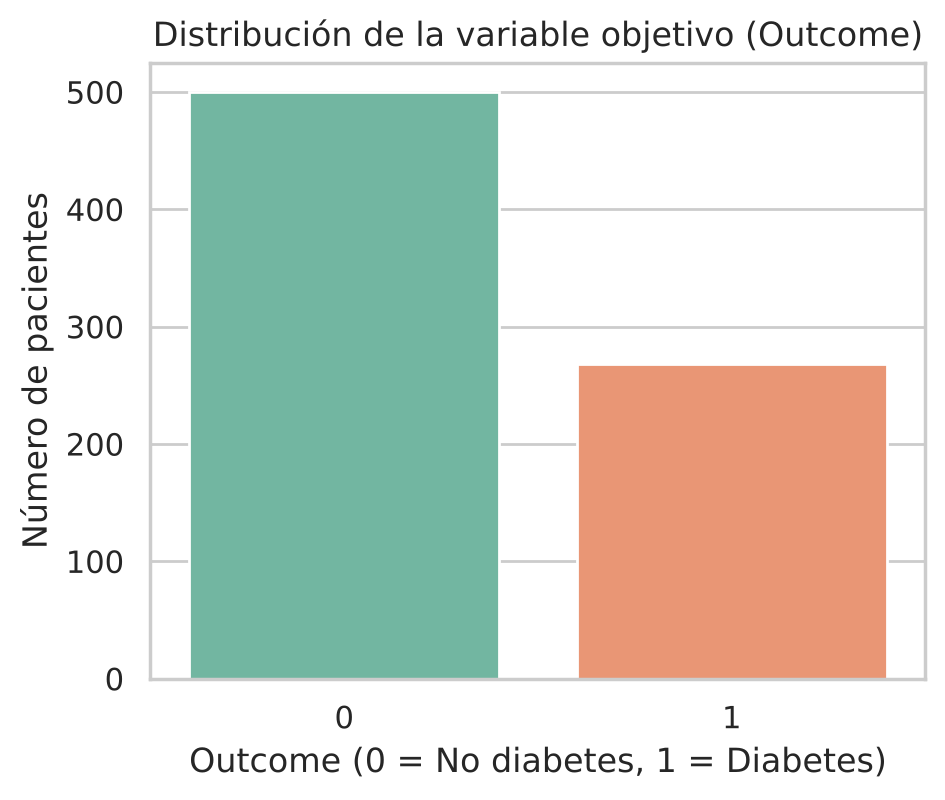

Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


In [11]:
# Visualización del balance de clases
plt.figure(figsize=(5,4))
sns.countplot(data=df, x="Outcome", hue="Outcome", palette="Set2", legend=False)
plt.title("Distribución de la variable objetivo (Outcome)")
plt.xlabel("Outcome (0 = No diabetes, 1 = Diabetes)")
plt.ylabel("Número de pacientes")
plt.show()

print(df["Outcome"].value_counts(normalize=True).round(3) * 100)


**Interpretación:** la variable objetivo tiene 500 casos sin diabetes (65.1 %) y 268 con diabetes (34.9 %). Este desbalance moderado se analiza con más detalle en la sección 5.1 y se tiene en cuenta en la división de los datos y en la elección de métricas.

## 4. Preparación de los datos

En esta sección se define la **versión final de los datos** que se usa en el EDA y en el entrenamiento. Se parte del dataset original cargado en la sección 3 (`df`) y se aplican únicamente transformaciones justificadas.

### 4.1 Valores faltantes ocultos

Como se identificó en el primer avance, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` y `BMI` contienen ceros biológicamente imposibles. Se reemplazan por `NaN` para tratarlos como lo que son: valores faltantes. Esta es una regla fija que no se calcula a partir de los datos, por lo que puede aplicarse a todo el dataset antes de dividirlo sin generar fuga de información.

In [12]:
# Versión de trabajo: ceros imposibles convertidos en NaN (sin imputar)
cols_ceros_imposibles = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df_obs = pd.read_csv("diabetes.csv")
df_obs[cols_ceros_imposibles] = df_obs[cols_ceros_imposibles].replace(0, np.nan)

faltantes = pd.DataFrame({
    "faltantes": df_obs.isna().sum(),
    "porcentaje_(%)": (df_obs.isna().mean() * 100).round(1),
})
print(f"Registros: {len(df_obs)} | Registros con al menos un faltante: {df_obs.isna().any(axis=1).sum()} "
      f"({df_obs.isna().any(axis=1).mean() * 100:.1f} %)")
faltantes[faltantes["faltantes"] > 0]

Registros: 768 | Registros con al menos un faltante: 376 (49.0 %)


,faltantes,porcentaje_(%)
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


**Interpretación:** casi la mitad de los registros tiene al menos un valor faltante, concentrado sobre todo en `Insulin` y `SkinThickness`. Eliminar esas filas reduciría el dataset aproximadamente a la mitad, por lo que se mantiene la decisión del primer avance de **imputar con la mediana**, pero ahora calculándola solo con el conjunto de entrenamiento (sección 4.5).

In [13]:
# ¿Los faltantes se distribuyen igual en ambas clases?
(df_obs.groupby("Outcome")[cols_ceros_imposibles]
       .apply(lambda g: g.isna().mean() * 100)
       .round(1)
       .rename(index={0: "Outcome = 0 (%)", 1: "Outcome = 1 (%)"}))

,Glucose,BloodPressure,SkinThickness,Insulin,BMI
Outcome,,,,,
Outcome = 0 (%),0.6,3.8,27.8,47.2,1.8
Outcome = 1 (%),0.7,6.0,32.8,51.5,0.7


**Interpretación:** la proporción de faltantes es algo mayor en las pacientes con diabetes para `Insulin` y `SkinThickness`, pero las diferencias son de pocos puntos porcentuales. No hay evidencia de que la ausencia del dato por sí sola sea una señal fuerte del diagnóstico, por lo que en esta etapa no se agregan variables indicadoras de faltante. Se registra como un aspecto a revisar en el tercer corte.

### 4.2 Duplicados, tipos de datos, categorías, identificadores y fugas de información

In [14]:
print("Registros duplicados:", df_obs.duplicated().sum())
print("Tipos de datos:", df_obs.dtypes.astype(str).value_counts().to_dict())
print("Valores únicos de Outcome:", sorted(df_obs["Outcome"].unique()))
print("Valores negativos en alguna variable:", int((df_obs.select_dtypes("number") < 0).sum().sum()))

Registros duplicados: 0
Tipos de datos: {'float64': 6, 'int64': 3}
Valores únicos de Outcome: [np.int64(0), np.int64(1)]
Valores negativos en alguna variable: 0


- **Duplicados:** no hay registros duplicados.
- **Tipos y categorías:** todas las variables son numéricas; `Outcome` solo toma los valores 0 y 1. No hay variables de texto ni categorías inconsistentes, por lo que **no se requiere codificación** (*one-hot* o *label encoding*).
- **Identificadores:** el dataset no tiene columnas de identificación de pacientes; no hay variables que eliminar por ese motivo.
- **Fugas de información:** ninguna variable predictora se deriva de `Outcome`. El riesgo de fuga está en el **preprocesamiento**: si la mediana de imputación o los parámetros de escalamiento se calculan con todo el dataset, el modelo "ve" información del conjunto de prueba. Por eso ambos pasos se ajustan solo con los datos de entrenamiento mediante `Pipeline`.

### 4.3 Valores atípicos

Se identifican con el criterio del rango intercuartílico (IQR): un valor es atípico si está por debajo de Q1 − 1.5·IQR o por encima de Q3 + 1.5·IQR. El cálculo se hace sobre los valores observados (sin imputar). La revisión visual se presenta en el EDA (sección 5).

In [15]:
predictoras = [c for c in df_obs.columns if c != "Outcome"]

filas = []
mascara_atipico = pd.Series(False, index=df_obs.index)
for col in predictoras:
    q1, q3 = df_obs[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    m = (df_obs[col] < lim_inf) | (df_obs[col] > lim_sup)
    mascara_atipico |= m
    filas.append({
        "variable": col,
        "límite_inferior": round(lim_inf, 2),
        "límite_superior": round(lim_sup, 2),
        "mínimo": df_obs[col].min(),
        "máximo": df_obs[col].max(),
        "n_atípicos": int(m.sum()),
        "%_con_diabetes_entre_atípicos": round(df_obs.loc[m, "Outcome"].mean() * 100, 1) if m.any() else None,
    })

tabla_atipicos = pd.DataFrame(filas).set_index("variable")
print(f"Registros con al menos un atípico: {mascara_atipico.sum()} ({mascara_atipico.mean() * 100:.1f} %)")
print(f"% con diabetes entre esos registros: {df_obs.loc[mascara_atipico, 'Outcome'].mean() * 100:.1f} % "
      f"(en todo el dataset: {df_obs['Outcome'].mean() * 100:.1f} %)")
tabla_atipicos

Registros con al menos un atípico: 84 (10.9 %)
% con diabetes entre esos registros: 54.8 % (en todo el dataset: 34.9 %)


,límite_inferior,límite_superior,mínimo,máximo,n_atípicos,%_con_diabetes_entre_atípicos
variable,,,,,,
Pregnancies,-6.50,13.50,0.000,17.00,4,100.0
Glucose,36.00,204.00,44.000,199.00,0,NaN
BloodPressure,40.00,104.00,24.000,122.00,14,42.9
SkinThickness,1.00,57.00,7.000,99.00,3,66.7
Insulin,-94.38,360.62,14.000,846.00,24,58.3
BMI,13.85,50.25,18.200,67.10,8,75.0
DiabetesPedigreeFunction,-0.33,1.20,0.078,2.42,29,58.6
Age,-1.50,66.50,21.000,81.00,9,22.2


**Decisión: se conservan los valores atípicos.** Razones:

1. **Son clínicamente posibles.** Valores como una insulina de 846 μU/ml, un IMC de 67.1 o una edad de 81 años son extremos, pero existen en la práctica clínica. El único valor de dudosa plausibilidad es un grosor de pliegue cutáneo de 99 mm; al ser un solo registro, se conserva y se señala como posible error de medición.
2. **Eliminarlos sesgaría el dataset.** Entre los registros con al menos un atípico, la proporción de pacientes con diabetes es mucho mayor que en el total, así que borrarlos eliminaría sobre todo casos positivos, que ya son la clase minoritaria.
3. **Los modelos elegidos los toleran.** El árbol de decisión y el random forest dividen por umbrales y son poco sensibles a valores extremos; en la regresión logística, el escalamiento reduce el efecto de las diferencias de escala.

No se aplica recorte (*capping*) ni transformación logarítmica en esta entrega. La asimetría de `Insulin` y `DiabetesPedigreeFunction` se registra como posible mejora para el tercer corte.

### 4.4 Versión final de los datos para modelar

- **Registros:** 768 (no se eliminó ninguno).
- **Variables predictoras (X):** las 8 originales.
- **Variable objetivo (y):** `Outcome`.
- **Faltantes:** se mantienen como `NaN` hasta la imputación dentro del `Pipeline`.
- **Datos para el EDA:** `df_obs`, con valores observados (sin imputar).

In [16]:
X = df_obs[predictoras]
y = df_obs["Outcome"]
print("X:", X.shape, "| y:", y.shape)
print("Distribución de y:", y.value_counts().to_dict())

X: (768, 8) | y: (768,)
Distribución de y: {0: 500, 1: 268}


### 4.5 Transformaciones y preprocesamiento por modelo

| Transformación | Se aplica a | Ajustada con | Razón |
|---|---|---|---|
| Ceros imposibles → `NaN` | `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI` | Regla fija | Son faltantes ocultos |
| Imputación con la mediana | Todas las predictoras (todos los modelos) | Solo entrenamiento | La mediana es robusta a la asimetría y los atípicos |
| Escalamiento (`StandardScaler`) | Regresión logística | Solo entrenamiento | La logística es sensible a la escala; los árboles no |
| Codificación categórica | No aplica | — | No hay variables categóricas predictoras |

Los preprocesadores se definen aquí y se ajustan en la sección de modelado, después de dividir los datos.

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Para la regresión logística: imputación + escalamiento
preproc_escalado = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalamiento", StandardScaler()),
])

# Para los modelos basados en árboles: solo imputación
preproc_arboles = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
])

preproc_escalado

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputacion', ...), ('escalamiento', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto a

## 5. Análisis Exploratorio de Datos (EDA)

El EDA se orienta a la pregunta de investigación: **qué variables diferencian a las pacientes con y sin diabetes, cómo se relacionan entre sí y qué implicaciones tiene esto para el modelado**. Se usa `df_obs` (valores observados, sin imputar), por lo que cada gráfica y estadístico considera solo los datos disponibles de cada variable. Los resultados describen **asociaciones**, no relaciones causales.

In [18]:
# Configuración común de las gráficas del EDA
etiquetas_outcome = {0: "Sin diabetes (0)", 1: "Con diabetes (1)"}
colores_outcome = {0: "#4C78A8", 1: "#E45756"}
df_eda = df_obs.copy()
df_eda["Diagnóstico"] = df_eda["Outcome"].map(etiquetas_outcome)
paleta_dx = {etiquetas_outcome[k]: v for k, v in colores_outcome.items()}
orden_dx = [etiquetas_outcome[0], etiquetas_outcome[1]]

### 5.1 Variable objetivo y desbalance de clases

La gráfica muestra cuántas pacientes hay en cada clase de `Outcome`, para dimensionar el desbalance.

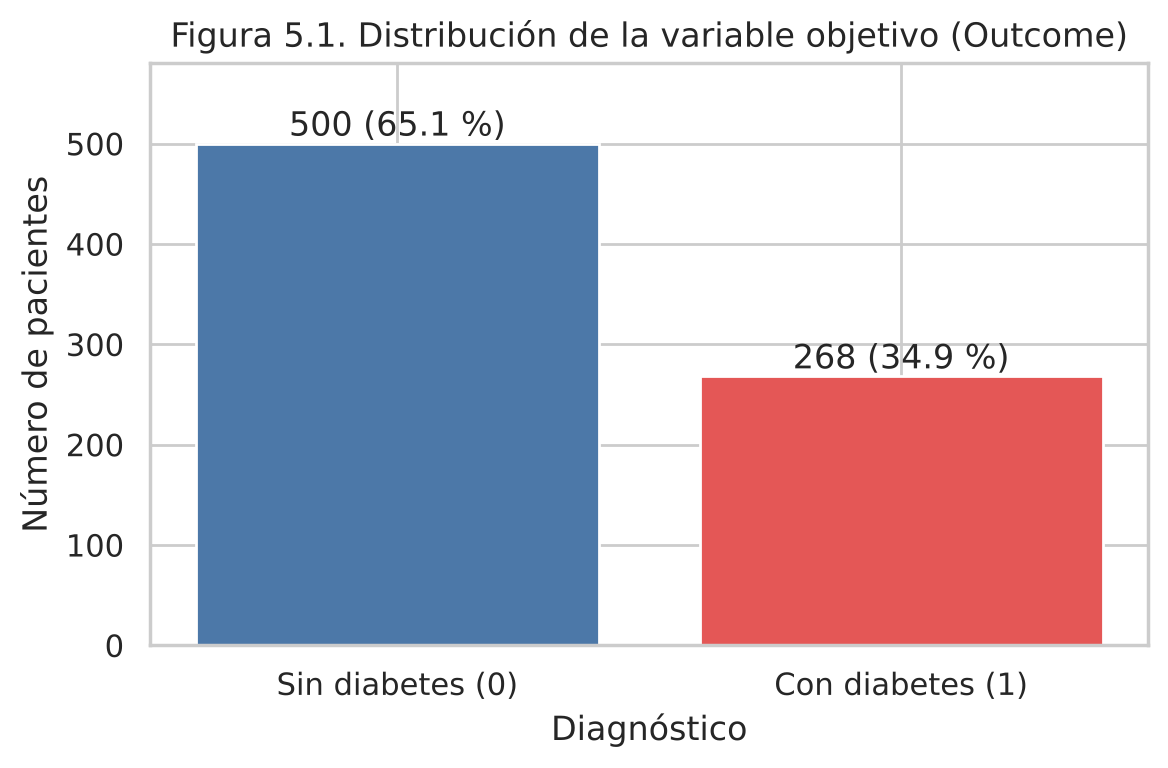

Razón de desbalance (clase 0 / clase 1): 1.87


In [19]:
# 5.1 Distribución de la variable objetivo
conteo = df_obs["Outcome"].value_counts().sort_index()
porcentaje = (conteo / conteo.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar([etiquetas_outcome[i] for i in conteo.index], conteo.values,
                color=[colores_outcome[i] for i in conteo.index])
for barra, n, p in zip(barras, conteo.values, porcentaje.values):
    ax.text(barra.get_x() + barra.get_width() / 2, n + 8, f"{n} ({p} %)", ha="center")
ax.set(title="Figura 5.1. Distribución de la variable objetivo (Outcome)",
       xlabel="Diagnóstico", ylabel="Número de pacientes", ylim=(0, 580))
plt.tight_layout()
plt.show()

print(f"Razón de desbalance (clase 0 / clase 1): {conteo[0] / conteo[1]:.2f}")

**Interpretación:** hay 500 pacientes sin diabetes (65.1 %) y 268 con diabetes (34.9 %), es decir, aproximadamente 1.87 negativas por cada positiva. Es un desbalance moderado con dos consecuencias para el modelado: (1) un modelo que prediga siempre "sin diabetes" obtendría un *accuracy* cercano al 65 % sin detectar ningún caso, por lo que el *accuracy* no basta para comparar modelos; y (2) conviene dividir los datos de forma **estratificada** y usar pesos de clase balanceados para que la clase minoritaria no quede subrepresentada en el entrenamiento.

### 5.2 Distribución de las predictoras según el diagnóstico

Cada panel muestra la distribución de una predictora para las dos clases. Se usa densidad (y no conteo) para que las curvas sean comparables aunque las clases tengan distinto tamaño.

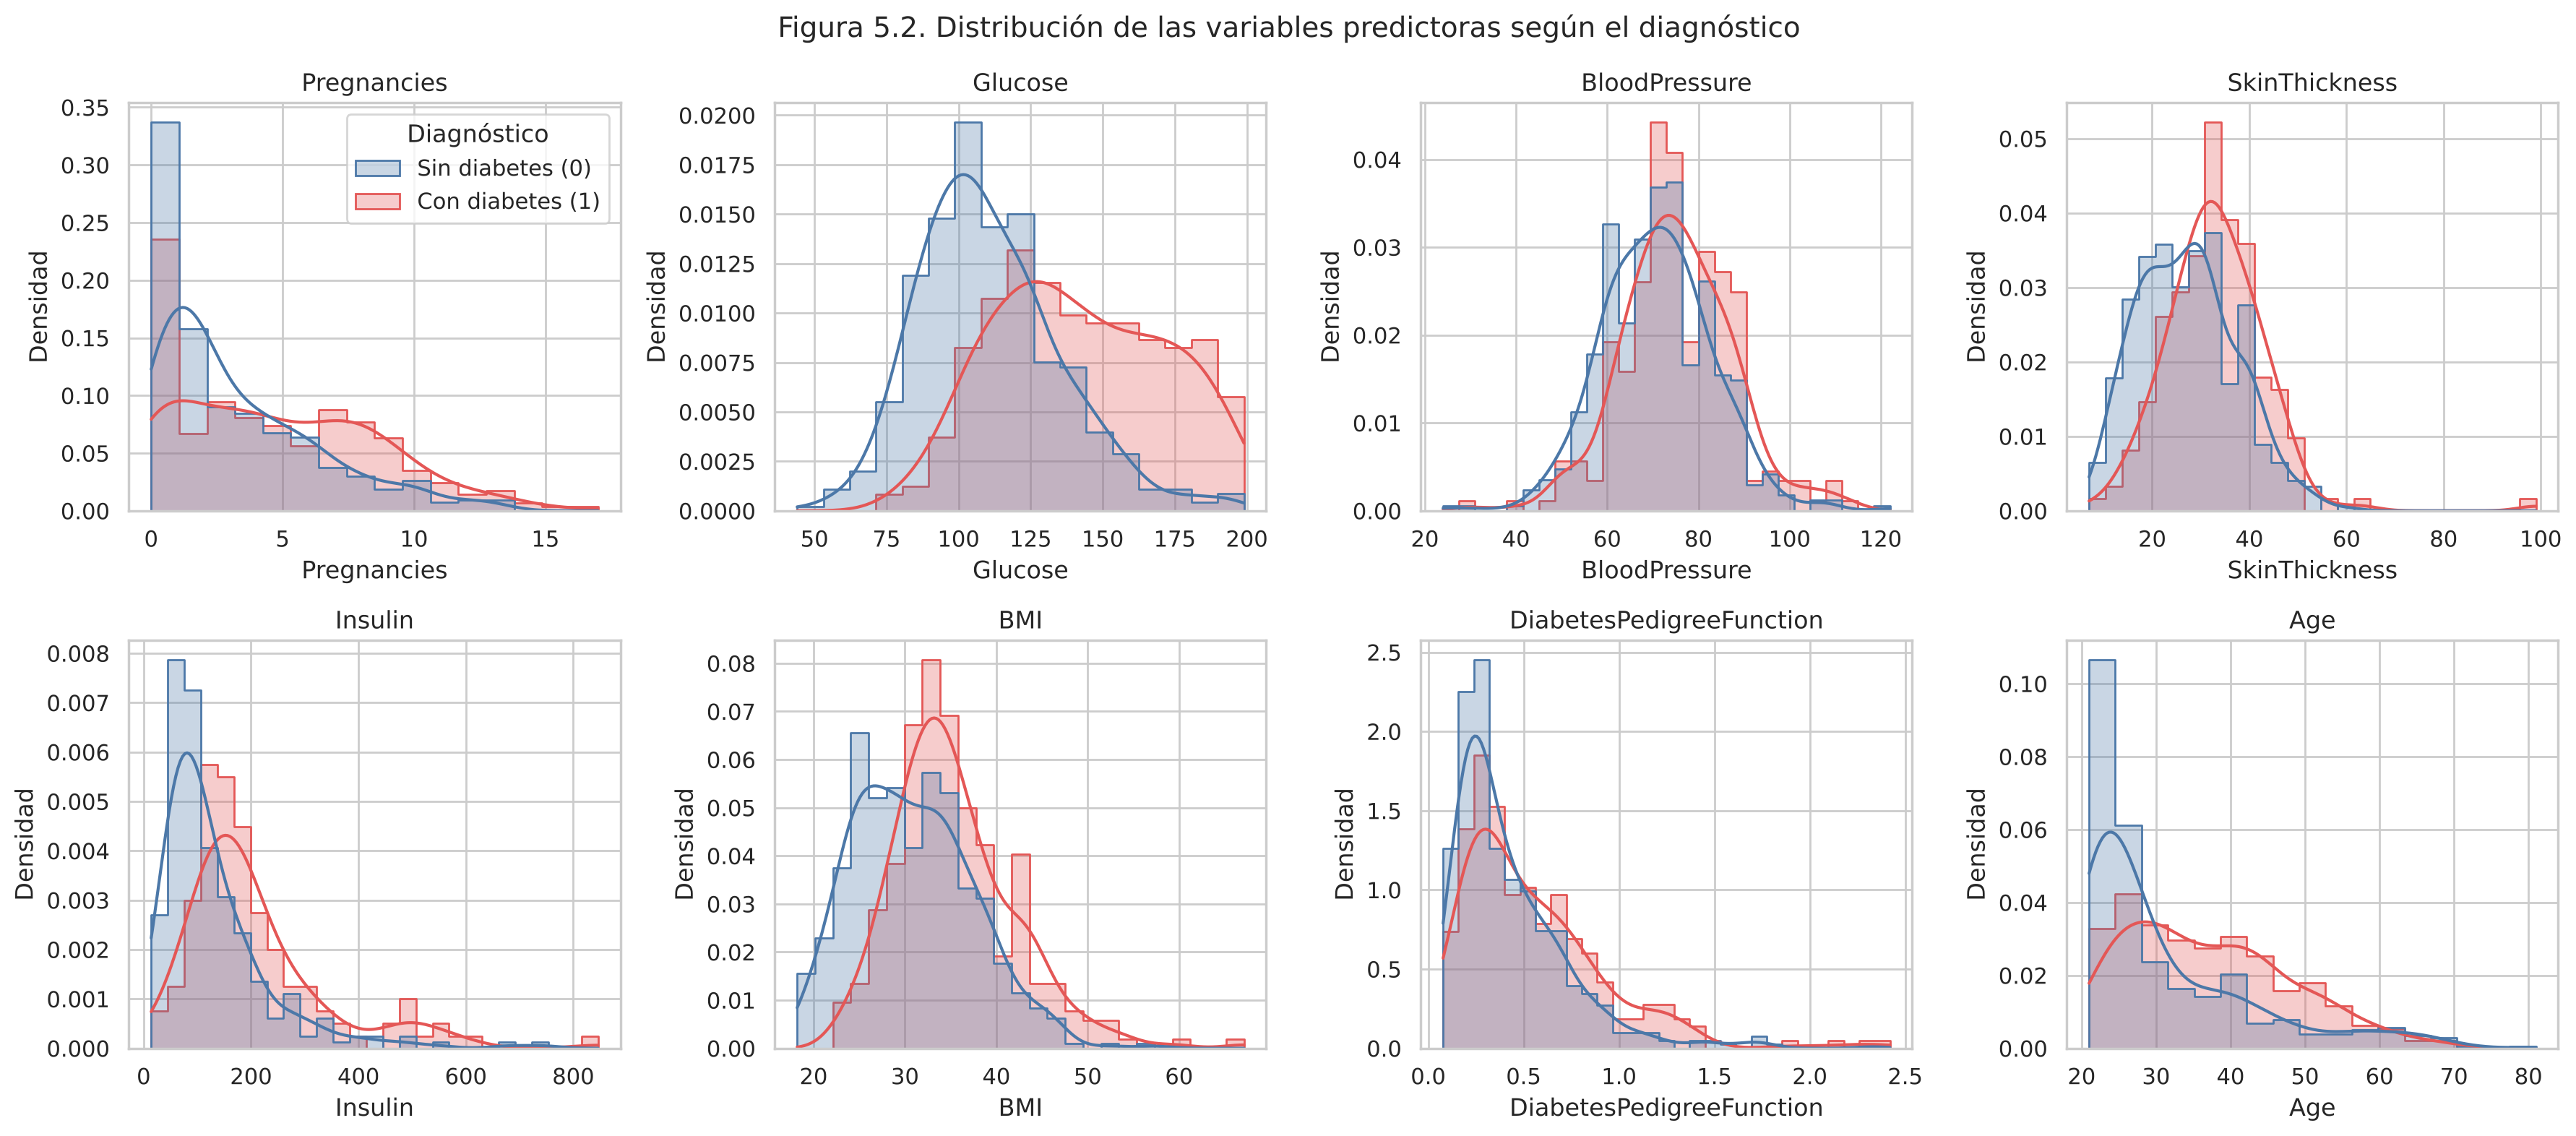

,asimetría
Insulin,2.17
DiabetesPedigreeFunction,1.92
Age,1.13
Pregnancies,0.90
SkinThickness,0.69
BMI,0.59
Glucose,0.53
BloodPressure,0.13


In [20]:
# 5.2 Distribución de cada predictora según el diagnóstico (valores observados)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), predictoras):
    sns.histplot(data=df_eda, x=col, hue="Diagnóstico", hue_order=orden_dx, palette=paleta_dx,
                 stat="density", common_norm=False, kde=True, element="step", alpha=0.3, ax=ax)
    ax.set(title=col, xlabel=col, ylabel="Densidad")
    if col != predictoras[0]:
        ax.get_legend().remove()
fig.suptitle("Figura 5.2. Distribución de las variables predictoras según el diagnóstico", fontsize=14)
plt.tight_layout()
plt.show()

asimetria = df_obs[predictoras].skew().round(2).sort_values(ascending=False)
asimetria.to_frame("asimetría")

**Interpretación:**
- **`Glucose`** es la variable que mejor separa las clases: la distribución de las pacientes con diabetes está claramente desplazada hacia valores altos, aunque hay superposición entre aproximadamente 100 y 150 mg/dL.
- **`BMI`**, **`Age`**, **`Insulin`** y **`Pregnancies`** también se desplazan hacia valores mayores en las pacientes con diabetes, pero con mucha más superposición.
- **`BloodPressure`** y **`DiabetesPedigreeFunction`** muestran las curvas más parecidas entre grupos.
- Varias variables son **asimétricas a la derecha** (tabla): `Insulin` (2.17), `DiabetesPedigreeFunction` (1.92) y `Age` (1.13). Esto respalda usar la **mediana** para imputar y no la media.

### 5.3 Comparación numérica entre grupos

Para complementar la figura anterior se comparan las medianas de cada predictora entre los dos grupos y se aplica la prueba de Mann-Whitney U, que no supone normalidad (adecuada por la asimetría observada). La tabla está ordenada del valor p más pequeño al más grande.

In [21]:
# 5.3 Comparación de las predictoras entre grupos
from scipy.stats import mannwhitneyu

filas = []
for col in predictoras:
    g0 = df_obs.loc[df_obs["Outcome"] == 0, col].dropna()
    g1 = df_obs.loc[df_obs["Outcome"] == 1, col].dropna()
    _, p = mannwhitneyu(g0, g1, alternative="two-sided")
    filas.append({
        "variable": col,
        "mediana_sin_diabetes": g0.median(),
        "mediana_con_diabetes": g1.median(),
        "diferencia_de_medianas": g1.median() - g0.median(),
        "n_observados": len(g0) + len(g1),
        "p_valor_Mann-Whitney": p,
    })

comparacion_grupos = pd.DataFrame(filas).set_index("variable").sort_values("p_valor_Mann-Whitney")
comparacion_grupos.style.format({
    "mediana_sin_diabetes": "{:.2f}", "mediana_con_diabetes": "{:.2f}",
    "diferencia_de_medianas": "{:.2f}", "p_valor_Mann-Whitney": "{:.2e}"})

,mediana_sin_diabetes,mediana_con_diabetes,diferencia_de_medianas,n_observados,p_valor_Mann-Whitney
variable,,,,,
Glucose,107.00,140.00,33.00,763,1.31e-40
Age,27.00,36.00,9.00,768,1.14e-17
BMI,30.10,34.30,4.20,757,1.82e-17
Insulin,102.50,169.50,67.00,394,7.48e-14
SkinThickness,27.00,32.00,5.00,541,6.96e-10
Pregnancies,2.00,4.00,2.00,768,3.75e-08
DiabetesPedigreeFunction,0.34,0.45,0.11,768,1.20e-06
BloodPressure,70.00,74.50,4.50,733,1.63e-06


**Interpretación:** las ocho predictoras presentan diferencias estadísticamente significativas entre grupos (todos los valores p < 0.001), pero la magnitud de la diferencia varía mucho. La más marcada es **`Glucose`**: la mediana pasa de 107 mg/dL en pacientes sin diabetes a 140 mg/dL en pacientes con diabetes (+33 mg/dL), con el valor p más pequeño. Le siguen **`BMI`** (30.1 frente a 34.3) y **`Age`** (27 frente a 36 años). `Insulin` también difiere bastante (102.5 frente a 169.5 μU/ml), aunque solo se observó en 394 de las 768 pacientes. `BloodPressure` es la variable con la diferencia más pequeña (70 frente a 74.5 mm Hg).

Un valor p muy pequeño indica que la diferencia difícilmente se debe al azar, pero **no** que la variable cause la diabetes ni que por sí sola permita clasificar bien. Con 768 registros, incluso diferencias pequeñas resultan significativas.

### 5.4 Revisión visual de valores atípicos

Los diagramas de caja permiten ver, en cada grupo, la mediana, el rango intercuartílico y los puntos fuera de 1.5·IQR (atípicos), complementando la tabla de la sección 4.3.

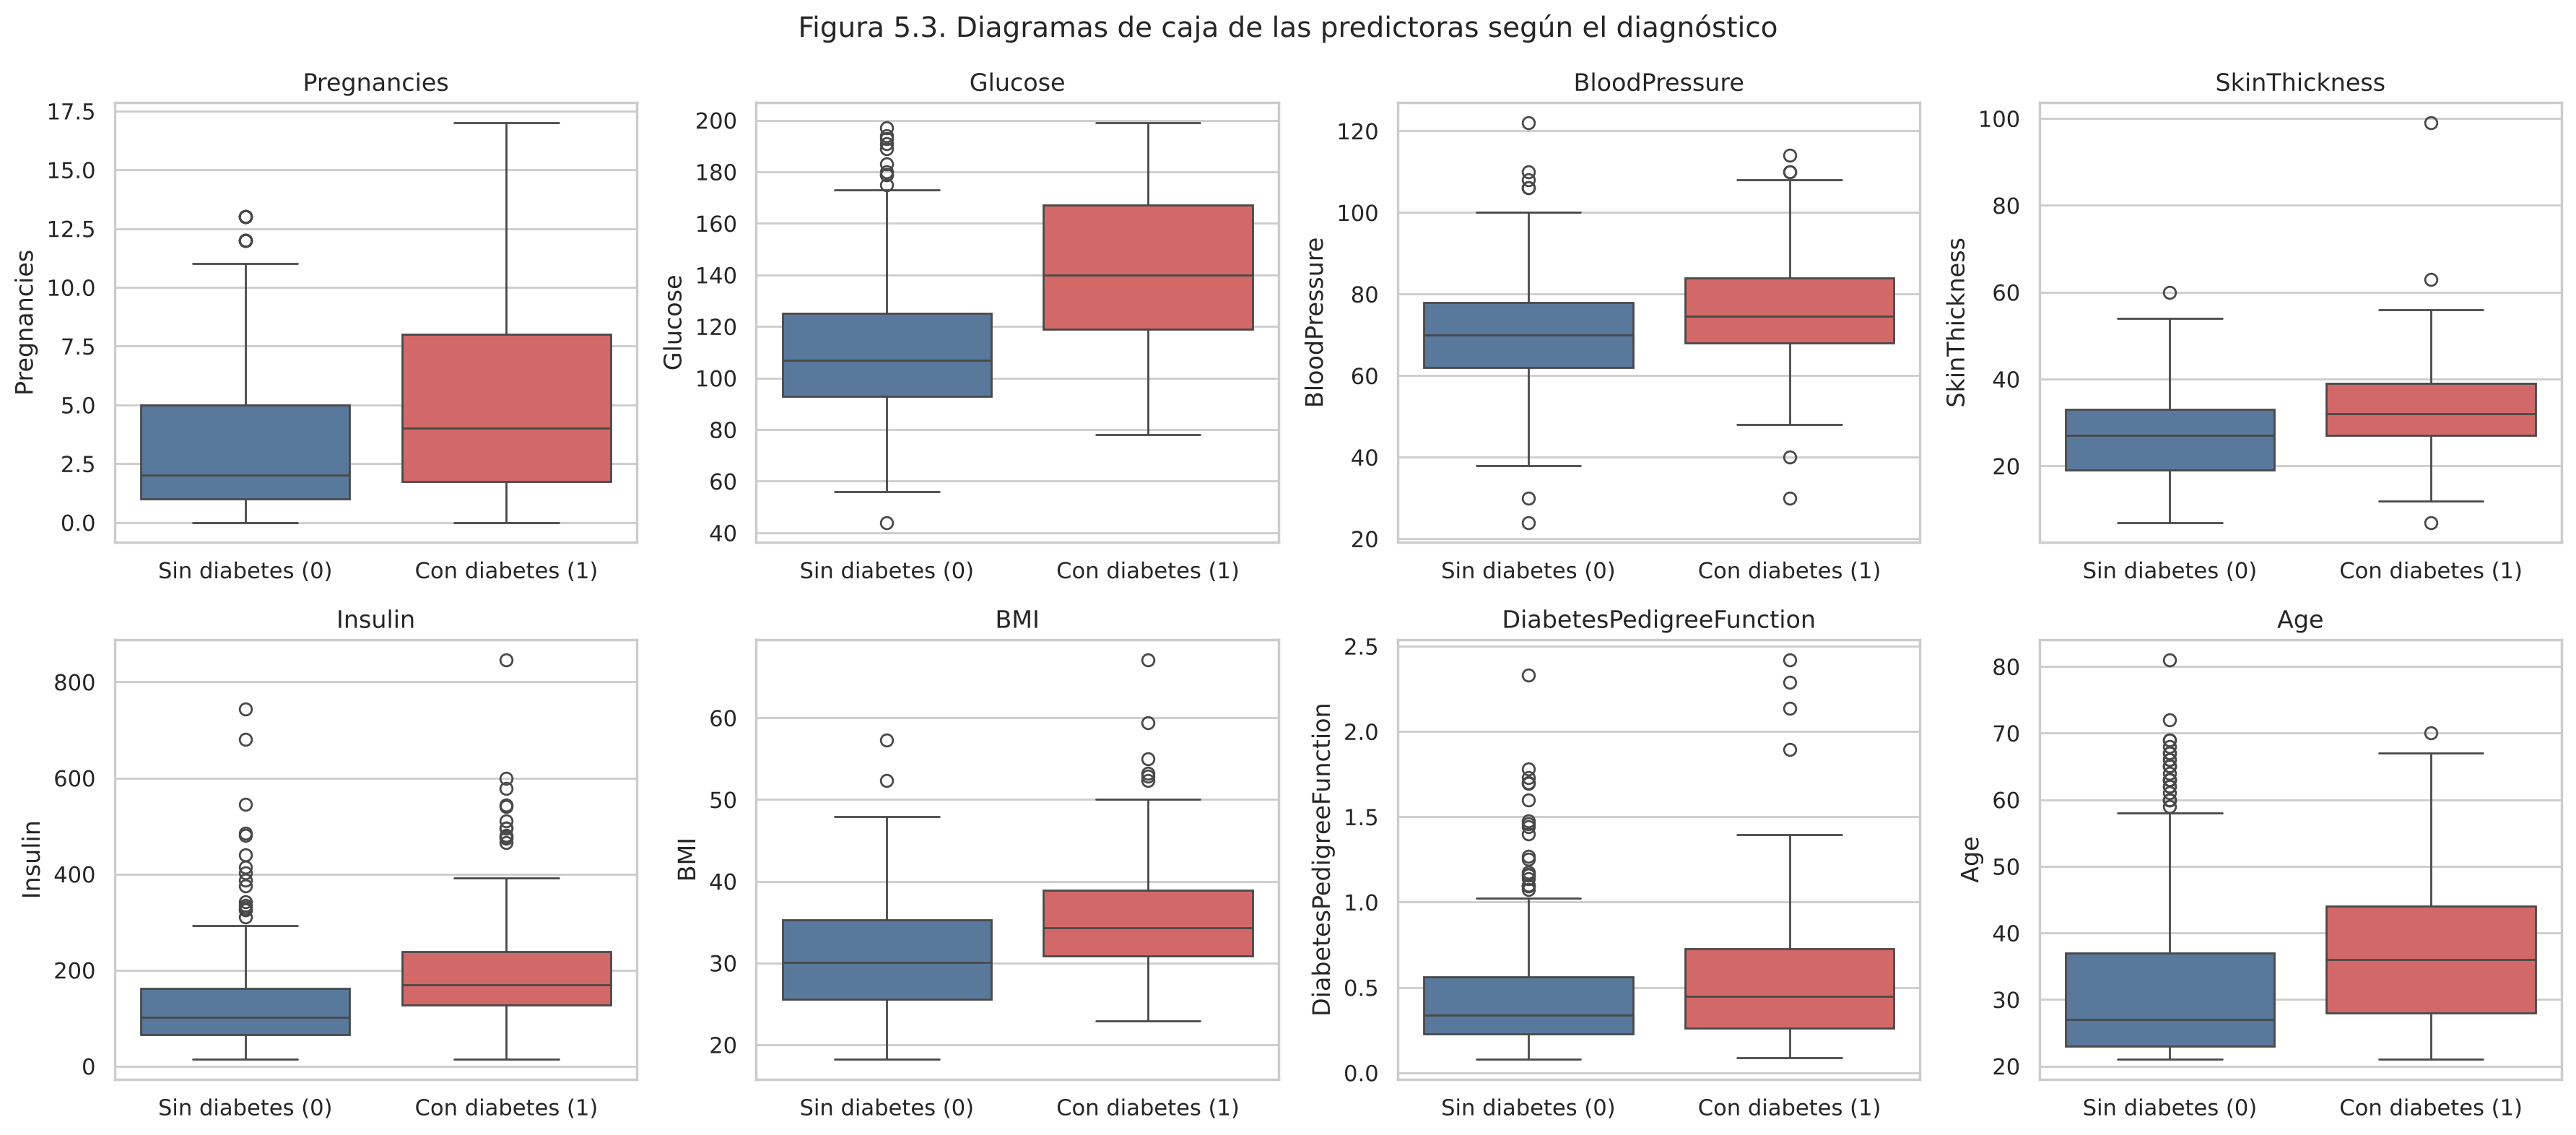

In [22]:
# 5.4 Revisión visual de atípicos por grupo
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), predictoras):
    sns.boxplot(data=df_eda, x="Diagnóstico", y=col, hue="Diagnóstico", order=orden_dx,
                hue_order=orden_dx, palette=paleta_dx, legend=False, ax=ax)
    ax.set(title=col, xlabel="", ylabel=col)
fig.suptitle("Figura 5.3. Diagramas de caja de las predictoras según el diagnóstico", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretación:** los atípicos se concentran en `Insulin`, `DiabetesPedigreeFunction`, `Age` y `BloodPressure`, y aparecen en ambos grupos. Se confirman los valores extremos señalados en la sección 4.3, como el registro de `SkinThickness` cercano a 100 mm, una insulina superior a 800 μU/ml y algunas presiones diastólicas por debajo de 40 mm Hg. Los grupos se superponen en todas las variables; incluso en `Glucose`, la caja de las pacientes con diabetes se superpone con el bigote superior de las pacientes sin diabetes. Esta superposición anticipa que ningún modelo clasificará perfectamente y que habrá errores en la zona intermedia. Se mantiene la decisión de **conservar los atípicos**, porque son plausibles y una parte importante pertenece a la clase positiva.

### 5.5 Relaciones entre variables y correlaciones

La matriz de la izquierda muestra la correlación de Pearson entre todas las variables (calculada con los pares de valores observados). La gráfica de la derecha aísla la correlación de cada predictora con `Outcome`. La tabla final lista los pares de predictoras con correlación de al menos 0.40 en valor absoluto, para revisar redundancia (multicolinealidad).

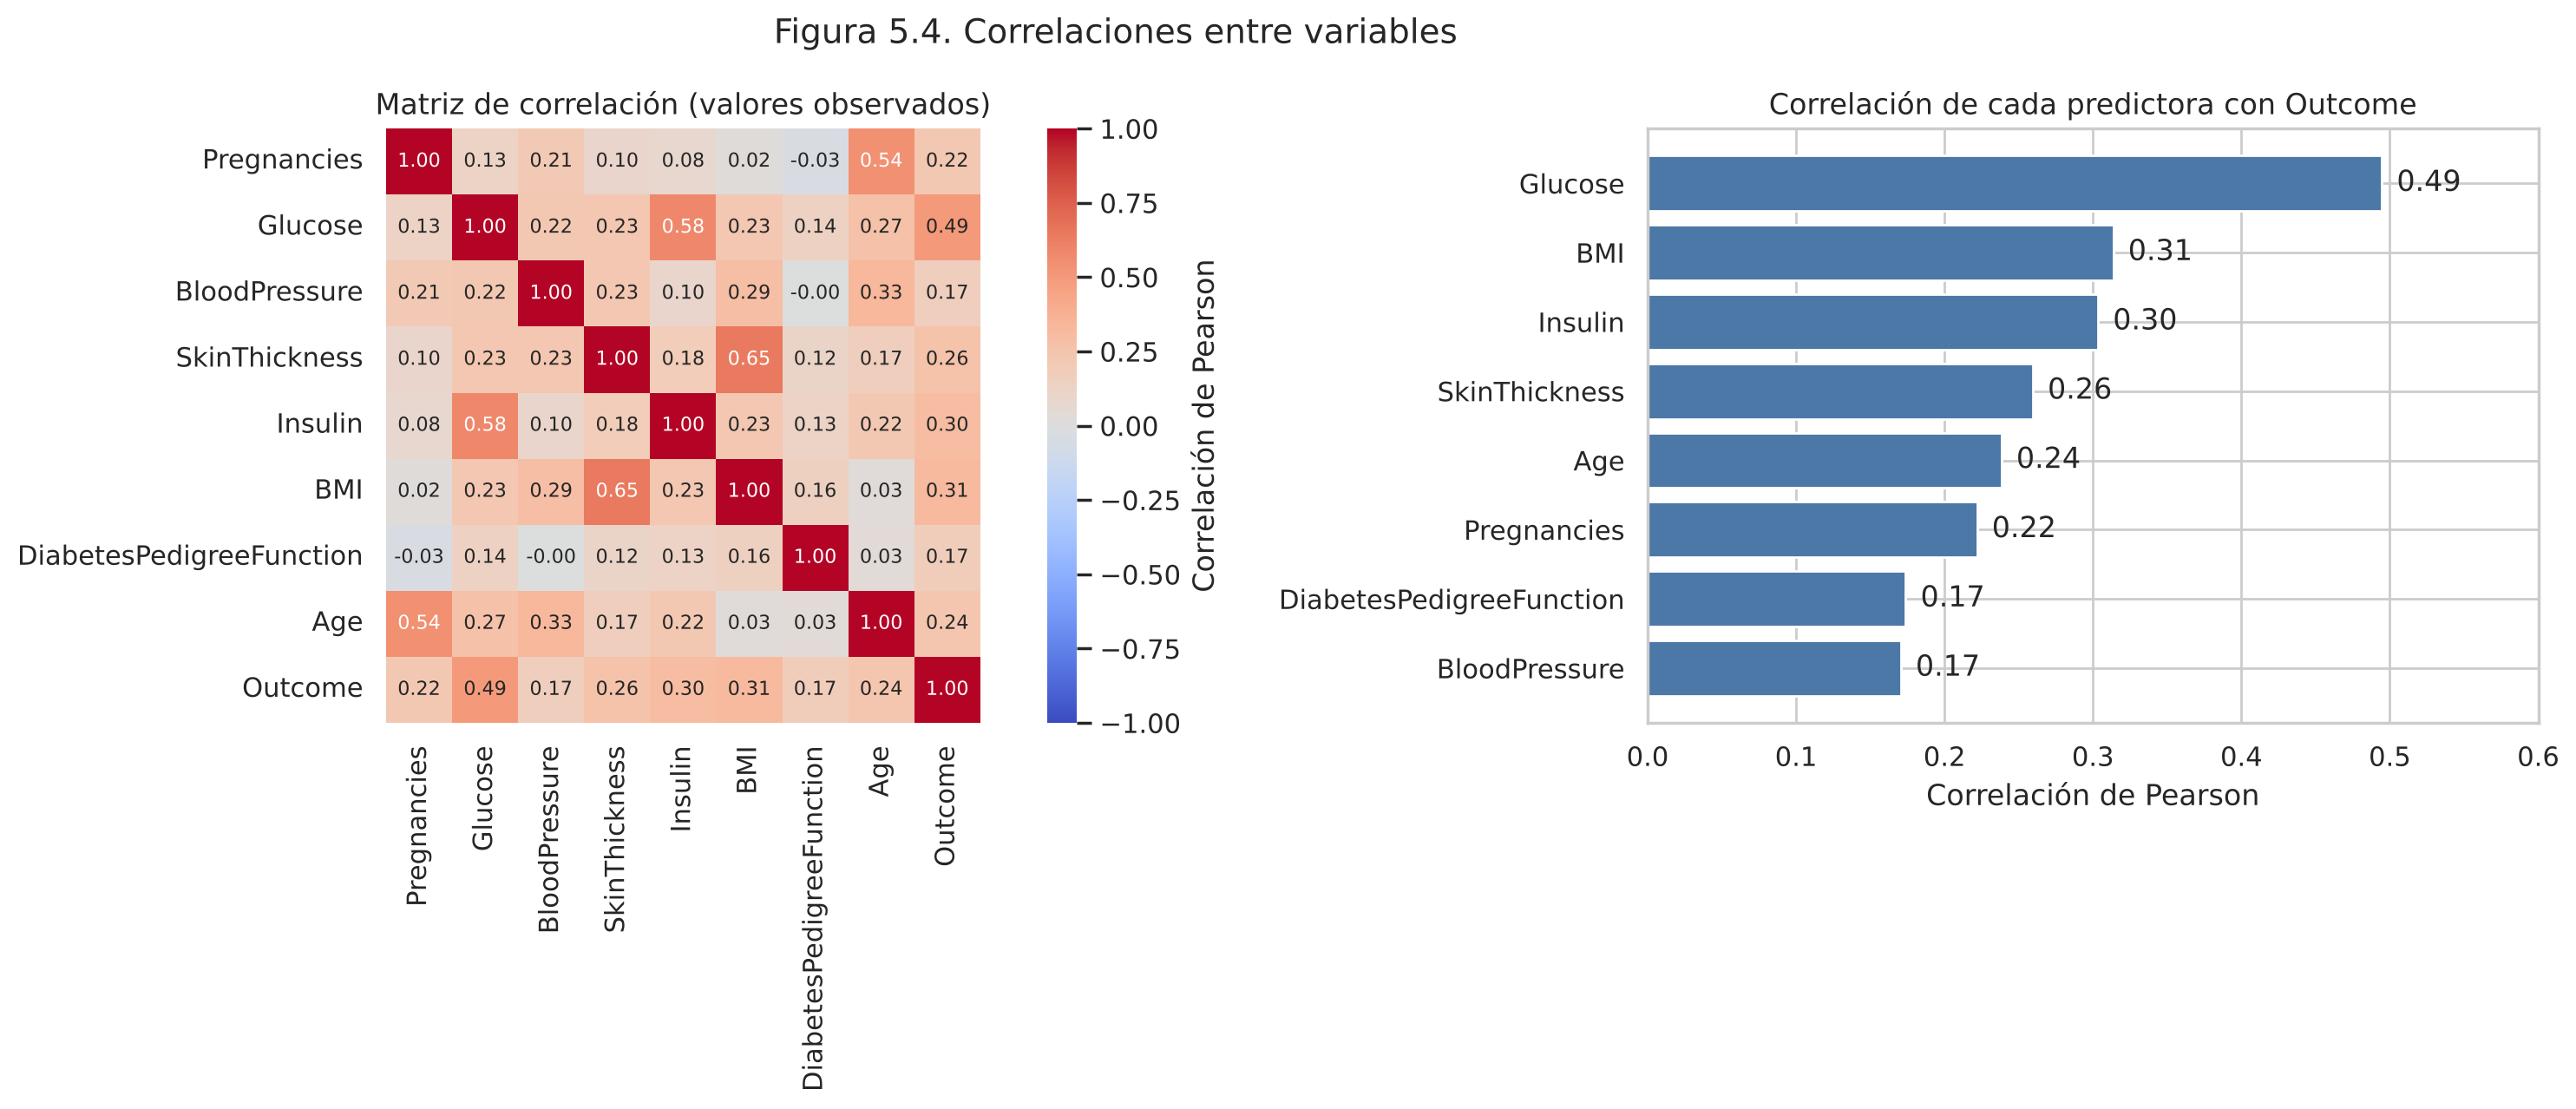

,level_0,level_1,correlación
29,SkinThickness,BMI,0.65
12,Glucose,Insulin,0.58
7,Pregnancies,Age,0.54


In [23]:
# 5.5 Correlaciones (Pearson, con los pares de valores observados)
correlaciones = df_obs.corr(method="pearson")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(correlaciones, annot=True, fmt=".2f", annot_kws={"size": 8}, cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"label": "Correlación de Pearson"}, ax=axes[0])
axes[0].set_title("Matriz de correlación (valores observados)")

corr_outcome = correlaciones["Outcome"].drop("Outcome").sort_values()
axes[1].barh(corr_outcome.index, corr_outcome.values, color="#4C78A8")
axes[1].set(title="Correlación de cada predictora con Outcome", xlabel="Correlación de Pearson", xlim=(0, 0.6))
for i, v in enumerate(corr_outcome.values):
    axes[1].text(v + 0.01, i, f"{v:.2f}", va="center")
fig.suptitle("Figura 5.4. Correlaciones entre variables", fontsize=14)
plt.tight_layout()
plt.show()

# Pares de predictoras con correlación moderada o alta
pares = (correlaciones.drop(index="Outcome", columns="Outcome")
         .where(np.triu(np.ones((8, 8), dtype=bool), k=1)).stack()
         .rename("correlación").reset_index())
pares[pares["correlación"].abs() >= 0.4].sort_values("correlación", ascending=False).round(2)

**Interpretación:**
- **Con `Outcome`:** `Glucose` tiene la correlación más alta (0.49), seguida de `BMI` (0.31) e `Insulin` (0.30). `BloodPressure` (0.17) y `DiabetesPedigreeFunction` (0.17) son las más débiles. Todas son positivas, lo que coincide con las diferencias de medianas de la sección 5.3. El valor de `Glucose` es prácticamente igual al reportado en el primer avance con datos imputados (~0.49), así que esa conclusión se mantiene.
- **Entre predictoras:** hay tres pares con correlación moderada: `SkinThickness`–`BMI` (0.65), `Glucose`–`Insulin` (0.58) y `Pregnancies`–`Age` (0.54). Ninguna supera 0.7, por lo que **no hay multicolinealidad severa** y se conservan todas las variables. Aun así, en la regresión logística los coeficientes de estos pares deben interpretarse con cautela porque comparten información.
- Pearson solo capta relaciones lineales; una correlación moderada no descarta relaciones no lineales, que los modelos basados en árboles pueden aprovechar.

### 5.6 Proporción de diabetes por rangos de glucosa y edad

Se agrupan las pacientes por rangos de las dos variables más asociadas en las secciones anteriores y se calcula el porcentaje con diabetes en cada rango. La línea discontinua marca el promedio general (34.9 %). Se indica el número de pacientes (n) de cada rango para valorar qué tan confiable es cada porcentaje.

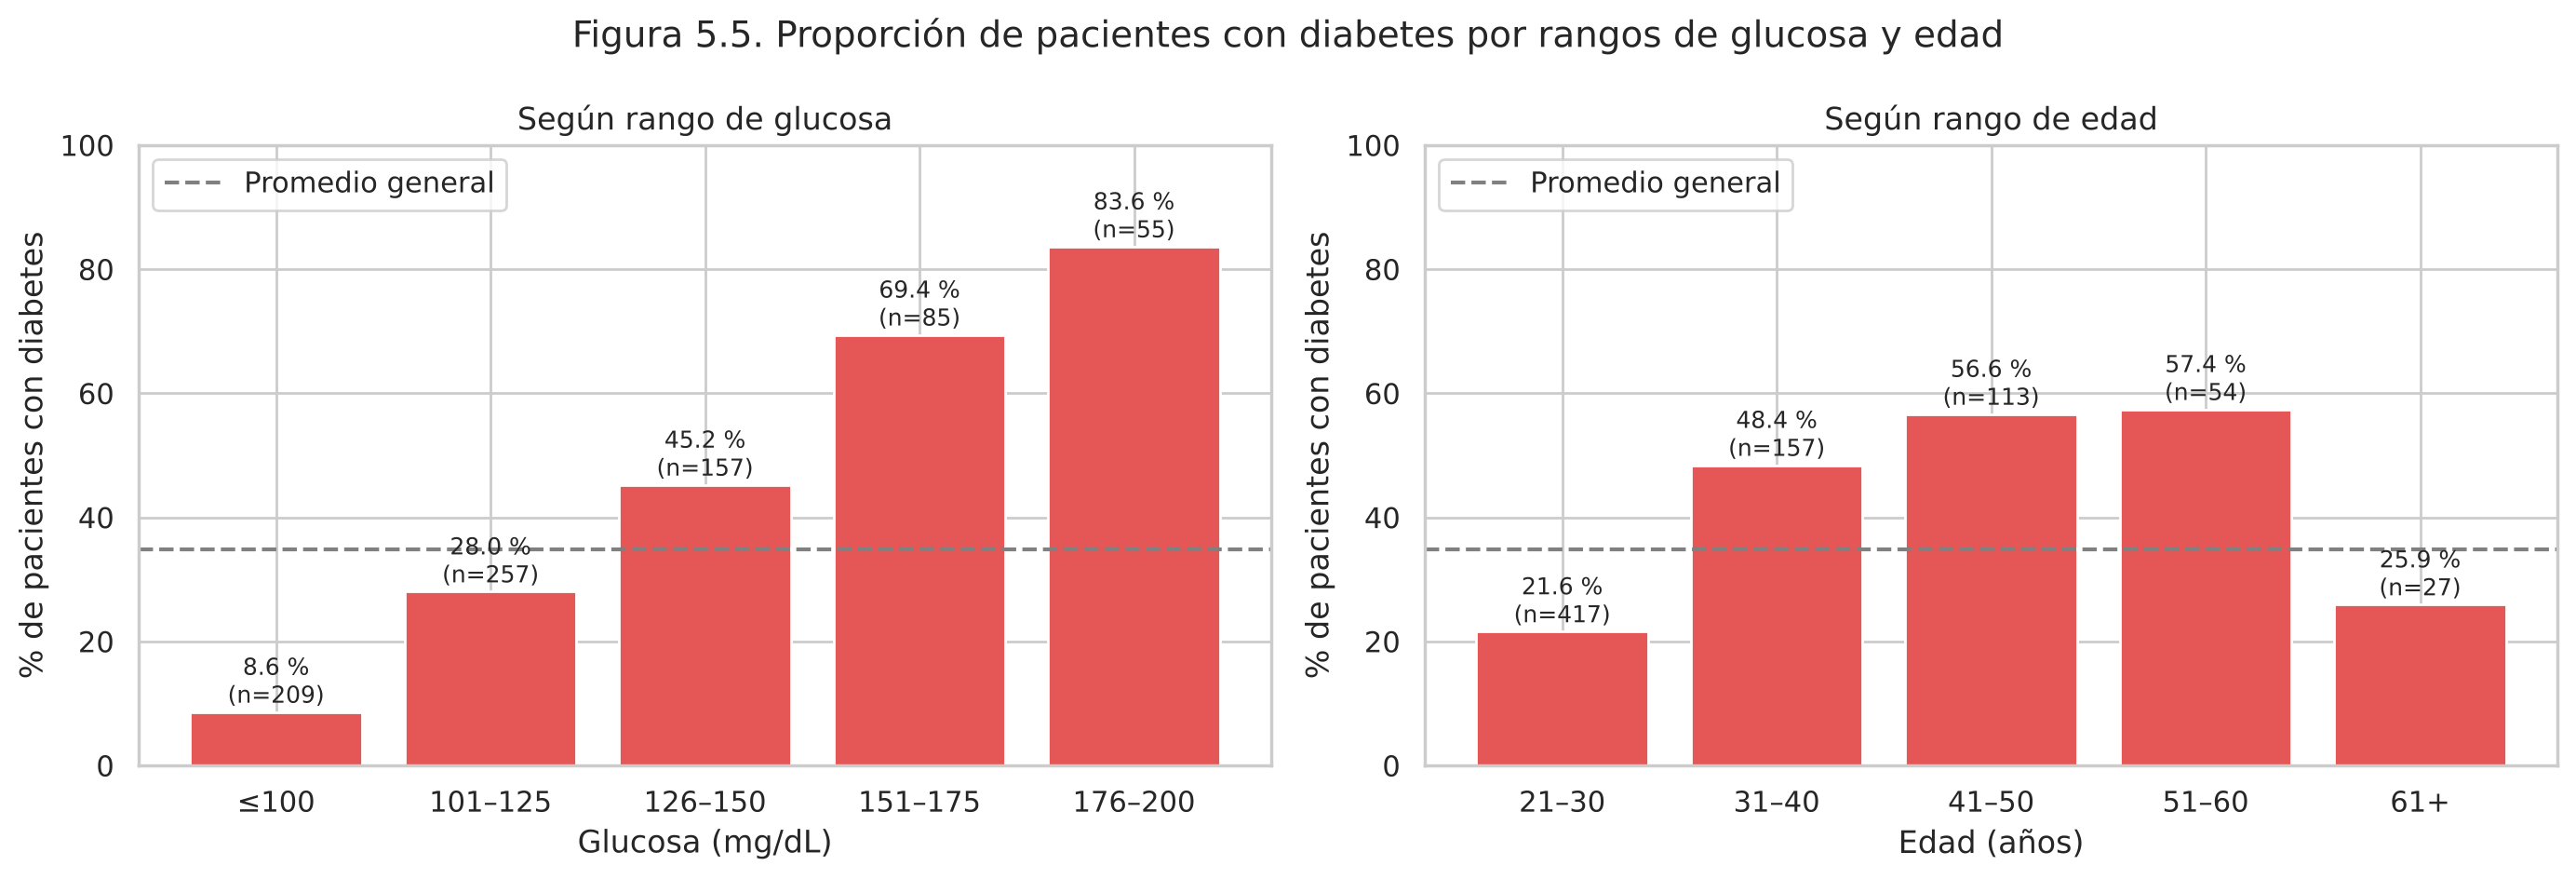

n  pct_diabetes
Glucosa ≤100     209           8.6
        101–125  257          28.0
        126–150  157          45.2
        151–175   85          69.4
        176–200   55          83.6
Edad    21–30    417          21.6
        31–40    157          48.4
        41–50    113          56.6
        51–60     54          57.4
        61+       27          25.9

In [24]:
# 5.6 Proporción de pacientes con diabetes por rangos de glucosa y de edad
df_tasas = df_obs.copy()
df_tasas["Rango_glucosa"] = pd.cut(df_tasas["Glucose"], bins=[0, 100, 125, 150, 175, 200],
                                   labels=["≤100", "101–125", "126–150", "151–175", "176–200"])
df_tasas["Rango_edad"] = pd.cut(df_tasas["Age"], bins=[20, 30, 40, 50, 60, 90],
                                labels=["21–30", "31–40", "41–50", "51–60", "61+"])

tasa_glucosa = df_tasas.groupby("Rango_glucosa", observed=True)["Outcome"].agg(n="size", pct_diabetes="mean")
tasa_edad = df_tasas.groupby("Rango_edad", observed=True)["Outcome"].agg(n="size", pct_diabetes="mean")
tasa_glucosa["pct_diabetes"] *= 100
tasa_edad["pct_diabetes"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, tabla, titulo, xlabel in [
        (axes[0], tasa_glucosa, "Según rango de glucosa", "Glucosa (mg/dL)"),
        (axes[1], tasa_edad, "Según rango de edad", "Edad (años)")]:
    barras = ax.bar(tabla.index.astype(str), tabla["pct_diabetes"], color="#E45756")
    for barra, pct, n in zip(barras, tabla["pct_diabetes"], tabla["n"]):
        ax.text(barra.get_x() + barra.get_width() / 2, pct + 1.5, f"{pct:.1f} %\n(n={n})", ha="center", fontsize=9)
    ax.axhline(df_obs["Outcome"].mean() * 100, ls="--", color="gray", label="Promedio general")
    ax.set(title=titulo, xlabel=xlabel, ylabel="% de pacientes con diabetes", ylim=(0, 100))
    ax.legend(loc="upper left")
fig.suptitle("Figura 5.5. Proporción de pacientes con diabetes por rangos de glucosa y edad", fontsize=14)
plt.tight_layout()
plt.show()

pd.concat({"Glucosa": tasa_glucosa, "Edad": tasa_edad}).round(1)

**Interpretación:**
- **Glucosa:** la proporción de diabetes **aumenta de forma sostenida** con la glucosa: 8.6 % con valores ≤ 100 mg/dL, 28.0 % entre 101 y 125, 45.2 % entre 126 y 150, 69.4 % entre 151 y 175 y 83.6 % entre 176 y 200. Es una relación aproximadamente monótona, adecuada para un modelo como la regresión logística.
- **Edad:** la proporción sube de 21.6 % (21–30 años) a 48.4 % (31–40), 56.6 % (41–50) y 57.4 % (51–60), pero **baja a 25.9 % en mayores de 60**. Esta relación **no es monótona**; sin embargo, el grupo de 61 años o más tiene solo 27 pacientes, por lo que su porcentaje es poco estable. Un patrón así es más fácil de capturar para un árbol de decisión que para un modelo lineal.

### 5.7 Relación conjunta entre glucosa e IMC

El diagrama de dispersión muestra cómo se combinan las dos variables con mayor asociación individual. Las líneas punteadas en 140 mg/dL y en un IMC de 30 se usan solo como referencia para dividir la gráfica en cuadrantes; la tabla muestra el porcentaje de diabetes en cada cuadrante.

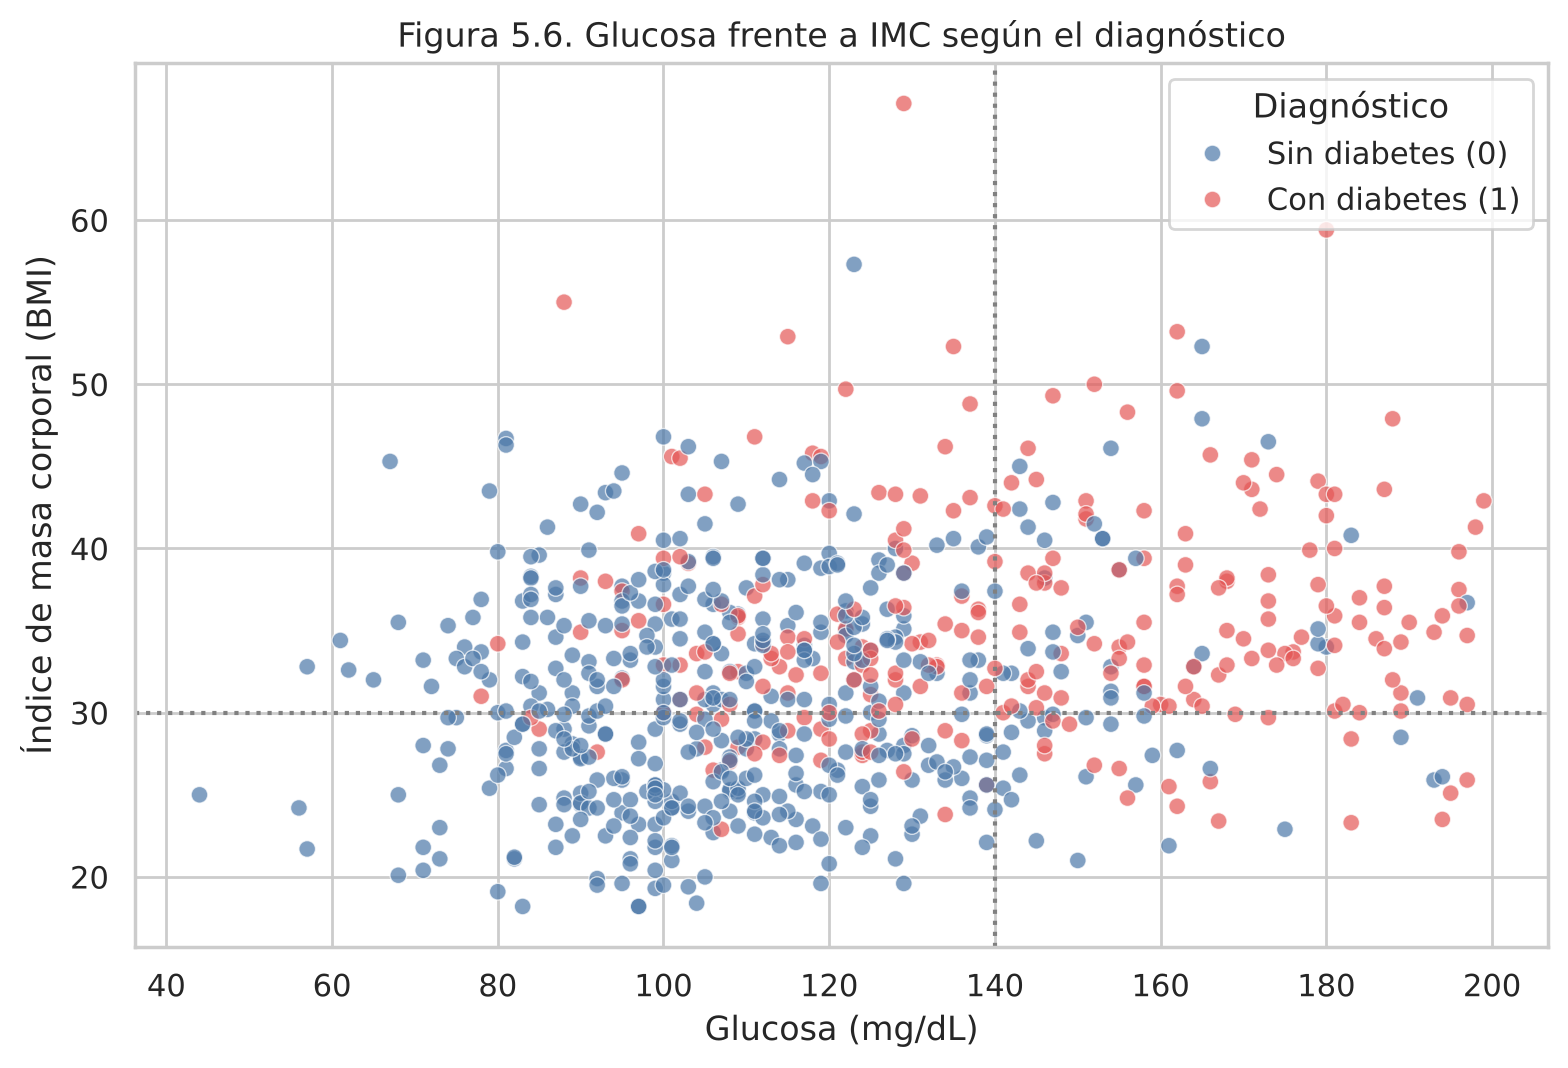

n  pct_diabetes
glucosa_alta  imc_alto                   
Glucosa > 140 IMC > 30  148          75.7
              IMC ≤ 30   44          45.5
Glucosa ≤ 140 IMC > 30  314          32.2
              IMC ≤ 30  246          12.6

In [25]:
# 5.7 Relación conjunta entre glucosa e IMC
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=df_eda, x="Glucose", y="BMI", hue="Diagnóstico", hue_order=orden_dx,
                palette=paleta_dx, alpha=0.7, ax=ax)
ax.axvline(140, ls=":", color="gray")
ax.axhline(30, ls=":", color="gray")
ax.set(title="Figura 5.6. Glucosa frente a IMC según el diagnóstico",
       xlabel="Glucosa (mg/dL)", ylabel="Índice de masa corporal (BMI)")
plt.tight_layout()
plt.show()

cuadrantes = df_obs.dropna(subset=["Glucose", "BMI"]).assign(
    glucosa_alta=lambda d: np.where(d["Glucose"] > 140, "Glucosa > 140", "Glucosa ≤ 140"),
    imc_alto=lambda d: np.where(d["BMI"] > 30, "IMC > 30", "IMC ≤ 30"))
(cuadrantes.groupby(["glucosa_alta", "imc_alto"])["Outcome"]
           .agg(n="size", pct_diabetes=lambda s: round(s.mean() * 100, 1)))

**Interpretación:** las pacientes con diabetes se concentran en la zona de glucosa alta, y la combinación de ambas variables aporta más información que cada una por separado: con glucosa > 140 e IMC > 30, el 75.7 % tiene diabetes; con glucosa > 140 e IMC ≤ 30, el 45.5 %; con glucosa ≤ 140 e IMC > 30, el 32.2 %; y con ambos valores por debajo de las referencias, solo el 12.6 %. Al mismo tiempo, hay casos positivos con glucosa e IMC bajos y casos negativos con valores altos, lo que confirma que las clases no son perfectamente separables.

### 5.8 Síntesis del EDA y decisiones para el modelado

| Hallazgo del EDA | Decisión de modelado |
|---|---|
| Desbalance moderado (65.1 % / 34.9 %) | División estratificada, pesos de clase balanceados y comparación con métricas por clase (recall, precisión y F1 de la clase 1), no solo *accuracy*. |
| `Glucose` es la variable más asociada al diagnóstico; `BMI` y `Age` le siguen | Se conservan las 8 variables; se espera que `Glucose` tenga el mayor peso en los modelos. |
| Relación aproximadamente monótona con la glucosa y no monótona con la edad | Se comparan un modelo lineal (regresión logística) con modelos basados en árboles (árbol de decisión y random forest), que pueden captar patrones no lineales. |
| Correlaciones entre predictoras ≤ 0.65 | No se eliminan variables por multicolinealidad. |
| Variables asimétricas y con atípicos plausibles | Imputación con la mediana; escalamiento solo para la regresión logística; atípicos conservados. |
| Fuerte superposición entre clases | Se esperan errores en la zona intermedia; se analizarán en las matrices de confusión. |

## 6. Selección y entrenamiento de modelos

### 6.1 Modelos seleccionados y justificación

El problema es una **clasificación binaria supervisada** (`Outcome` = 0 o 1) con 8 predictoras numéricas. Se seleccionan tres modelos estudiados en el curso, que representan enfoques diferentes:

| Modelo | Por qué es pertinente para este problema | Preprocesamiento |
|---|---|---|
| **Regresión logística** | Modelo lineal de referencia. Estima la probabilidad de diabetes y sus coeficientes indican la dirección de la asociación de cada variable. El EDA mostró una relación aproximadamente monótona entre la glucosa y el diagnóstico, que este modelo puede representar. | Imputación con la mediana + escalamiento |
| **Árbol de decisión** | Produce reglas explicables ("si la glucosa es mayor que…") y capta relaciones no lineales, como el patrón no monótono observado con la edad. | Imputación con la mediana |
| **Random forest** | Combina muchos árboles entrenados con muestras y variables aleatorias; suele ser más estable y generalizar mejor que un solo árbol. Se incluye porque se comprende su funcionamiento y permite comparar si un modelo de conjunto mejora al árbol individual. | Imputación con la mediana |

**Hiperparámetros:** el enunciado no exige optimizarlos, por lo que se fijan valores razonables y se justifican:
- Los tres modelos usan `class_weight="balanced"`, que da más peso a los errores en la clase minoritaria (diabetes) para compensar el desbalance 65/35 identificado en el EDA.
- El árbol de decisión se limita a `max_depth=4` y `min_samples_leaf=10` para evitar que memorice el entrenamiento y para que sus reglas puedan leerse.
- El random forest usa 300 árboles y `min_samples_leaf=5`.
- Se fija `random_state=42` en la división y en los modelos para que los resultados sean reproducibles.

### 6.2 Separación de predictoras y variable objetivo, y división entrenamiento/prueba

Se usan `X` (8 predictoras) e `y` (`Outcome`) definidas en la sección 4.4. Se reserva el **20 %** de los datos para prueba (proporción recomendada en el material del curso). La división es **estratificada** para que ambos conjuntos mantengan la proporción 65/35. El conjunto de prueba no se usa en ningún paso del entrenamiento ni del preprocesamiento.

In [26]:
from sklearn.model_selection import train_test_split

SEMILLA = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)

resumen_division = pd.DataFrame({
    "registros": [len(y_train), len(y_test)],
    "sin_diabetes (0)": [(y_train == 0).sum(), (y_test == 0).sum()],
    "con_diabetes (1)": [(y_train == 1).sum(), (y_test == 1).sum()],
    "%_con_diabetes": [round(y_train.mean() * 100, 1), round(y_test.mean() * 100, 1)],
}, index=["Entrenamiento", "Prueba"])
resumen_division

,registros,sin_diabetes (0),con_diabetes (1),%_con_diabetes
Entrenamiento,614,400,214,34.9
Prueba,154,100,54,35.1


**Interpretación:** el entrenamiento tiene 614 registros (400 sin diabetes y 214 con diabetes) y la prueba 154 (100 y 54). Gracias a la estratificación, ambos conjuntos conservan casi la misma proporción de casos positivos (34.9 % y 35.1 %), igual a la del dataset completo. Así, las métricas de prueba no se ven afectadas por una distribución de clases distinta a la real.

### 6.3 Construcción y entrenamiento de los modelos

Cada modelo se integra en un `Pipeline` con su preprocesamiento (sección 4.5). Al llamar a `fit` con los datos de entrenamiento, la mediana de imputación y los parámetros del escalamiento se calculan **solo** con esos datos, y luego se aplican sin cambios al conjunto de prueba.

In [27]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

modelos = {
    "Regresión logística": Pipeline(steps=[
        ("preprocesamiento", clone(preproc_escalado)),
        ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEMILLA)),
    ]),
    "Árbol de decisión": Pipeline(steps=[
        ("preprocesamiento", clone(preproc_arboles)),
        ("modelo", DecisionTreeClassifier(max_depth=4, min_samples_leaf=10,
                                          class_weight="balanced", random_state=SEMILLA)),
    ]),
    "Random forest": Pipeline(steps=[
        ("preprocesamiento", clone(preproc_arboles)),
        ("modelo", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                          class_weight="balanced", random_state=SEMILLA, n_jobs=-1)),
    ]),
}

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    print(f"{nombre}: entrenado con {len(X_train)} registros")

Regresión logística: entrenado con 614 registros
Árbol de decisión: entrenado con 614 registros


Random forest: entrenado con 614 registros


### 6.4 Predicciones sobre el conjunto de prueba

Se generan dos salidas por modelo: la **clase predicha** (umbral por defecto de 0.5) y la **probabilidad estimada** de diabetes, que se usará en la sección de evaluación.

In [28]:
predicciones = {nombre: m.predict(X_test) for nombre, m in modelos.items()}
probabilidades = {nombre: m.predict_proba(X_test)[:, 1] for nombre, m in modelos.items()}

# Cuántos casos predice cada modelo en cada clase, frente a la distribución real
conteo_predicciones = pd.DataFrame(
    {nombre: pd.Series(pred).value_counts().reindex([0, 1], fill_value=0) for nombre, pred in predicciones.items()}
).T
conteo_predicciones.columns = ["predichos_0", "predichos_1"]
conteo_predicciones.loc["Real (y_test)"] = [(y_test == 0).sum(), (y_test == 1).sum()]
conteo_predicciones

,predichos_0,predichos_1
Regresión logística,91,63
Árbol de decisión,72,82
Random forest,86,68
Real (y_test),100,54


**Interpretación:** en la prueba hay 54 pacientes con diabetes. La regresión logística predice 63 casos positivos, el random forest 68 y el árbol de decisión 82. Los tres modelos predicen **más positivos de los que realmente hay**, lo que es esperable al usar `class_weight="balanced"`: se aceptan más falsas alarmas a cambio de reducir los falsos negativos. El árbol es el que más positivos predice, por lo que es probable que tenga más falsas alarmas; esto se verifica con las matrices de confusión en la sección 7.

### 6.5 Qué aprendió cada modelo

Antes de evaluar el desempeño, se revisa qué variables usa cada modelo. Para la regresión logística se muestran los coeficientes (las variables están estandarizadas, por lo que son comparables entre sí); para el árbol de decisión y el random forest, la importancia de cada variable.

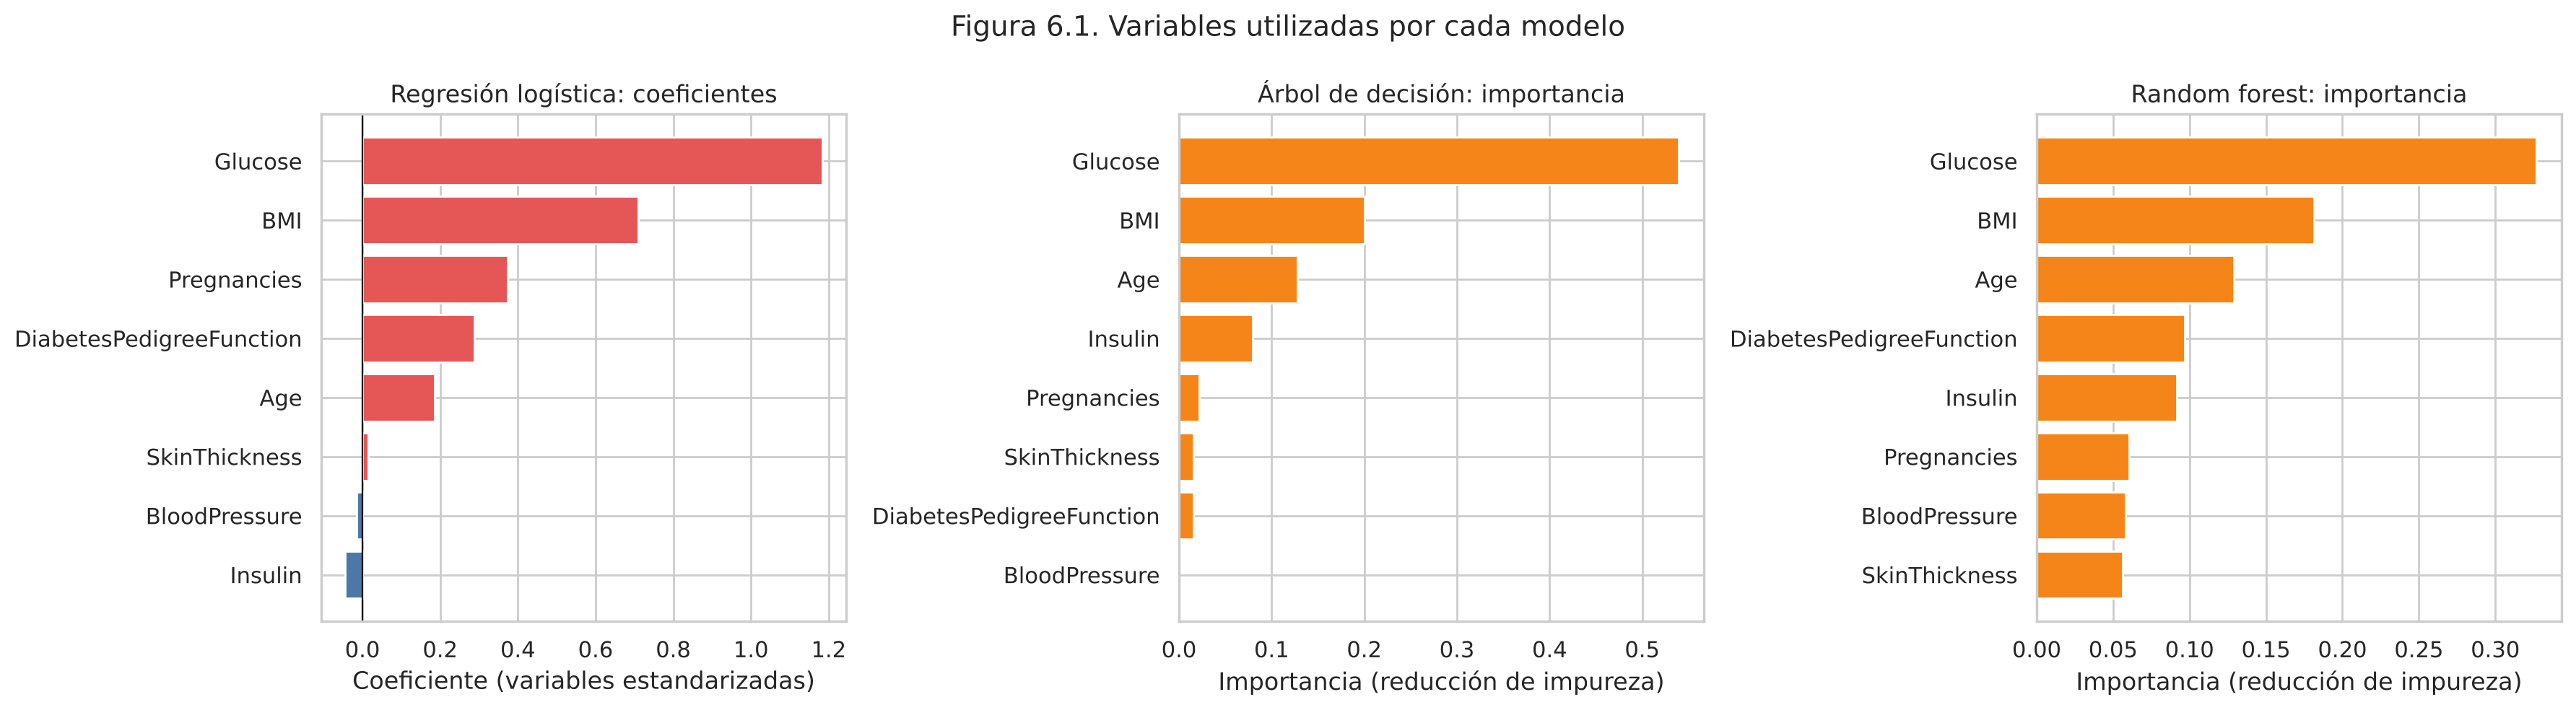

,coef_logística,importancia_árbol,importancia_random_forest
Glucose,1.183,0.540,0.327
BMI,0.710,0.200,0.181
Age,0.186,0.128,0.129
DiabetesPedigreeFunction,0.288,0.016,0.097
Insulin,-0.045,0.080,0.092
Pregnancies,0.373,0.022,0.060
BloodPressure,-0.015,0.000,0.058
SkinThickness,0.014,0.016,0.056


In [29]:
coef_log = pd.Series(modelos["Regresión logística"].named_steps["modelo"].coef_[0], index=predictoras)
imp_arbol = pd.Series(modelos["Árbol de decisión"].named_steps["modelo"].feature_importances_, index=predictoras)
imp_rf = pd.Series(modelos["Random forest"].named_steps["modelo"].feature_importances_, index=predictoras)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
coef_ord = coef_log.sort_values()
axes[0].barh(coef_ord.index, coef_ord.values, color=np.where(coef_ord.values >= 0, "#E45756", "#4C78A8"))
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set(title="Regresión logística: coeficientes", xlabel="Coeficiente (variables estandarizadas)")
for ax, imp, titulo in [(axes[1], imp_arbol, "Árbol de decisión: importancia"),
                        (axes[2], imp_rf, "Random forest: importancia")]:
    imp_ord = imp.sort_values()
    ax.barh(imp_ord.index, imp_ord.values, color="#F58518")
    ax.set(title=titulo, xlabel="Importancia (reducción de impureza)")
fig.suptitle("Figura 6.1. Variables utilizadas por cada modelo", fontsize=14)
plt.tight_layout()
plt.show()

pd.DataFrame({"coef_logística": coef_log, "importancia_árbol": imp_arbol,
              "importancia_random_forest": imp_rf}).round(3).sort_values("importancia_random_forest", ascending=False)

**Interpretación:**
- Los tres modelos coinciden en que **`Glucose`** es la variable más relevante (coeficiente de 1.183 en la logística; importancia de 0.540 en el árbol y 0.327 en el random forest), seguida de **`BMI`** y, en los modelos de árboles, de **`Age`**. Esto es coherente con el EDA (secciones 5.3 a 5.5).
- En la regresión logística, los coeficientes positivos indican que valores más altos de la variable se asocian con una mayor probabilidad estimada de diabetes, manteniendo las demás constantes. `Pregnancies` (0.373) y `DiabetesPedigreeFunction` (0.288) tienen coeficientes mayores que `Age` (0.186), posiblemente porque `Pregnancies` y `Age` están correlacionadas (0.54) y comparten información.
- `Insulin` (−0.045) y `BloodPressure` (−0.015) tienen coeficientes cercanos a cero. En el caso de `Insulin`, su correlación con `Glucose` (0.58) y la imputación del 48.7 % de sus valores pueden explicar por qué aporta poco una vez incluida la glucosa. Un coeficiente cercano a cero **no** significa que la variable no esté asociada con la diabetes por sí sola.
- El árbol concentra su decisión en pocas variables (`BloodPressure` tiene importancia 0); el random forest reparte la importancia entre todas, porque cada árbol ve subconjuntos aleatorios de variables.
- La importancia y los coeficientes describen cómo el modelo usa las variables para predecir; **no demuestran causalidad**.

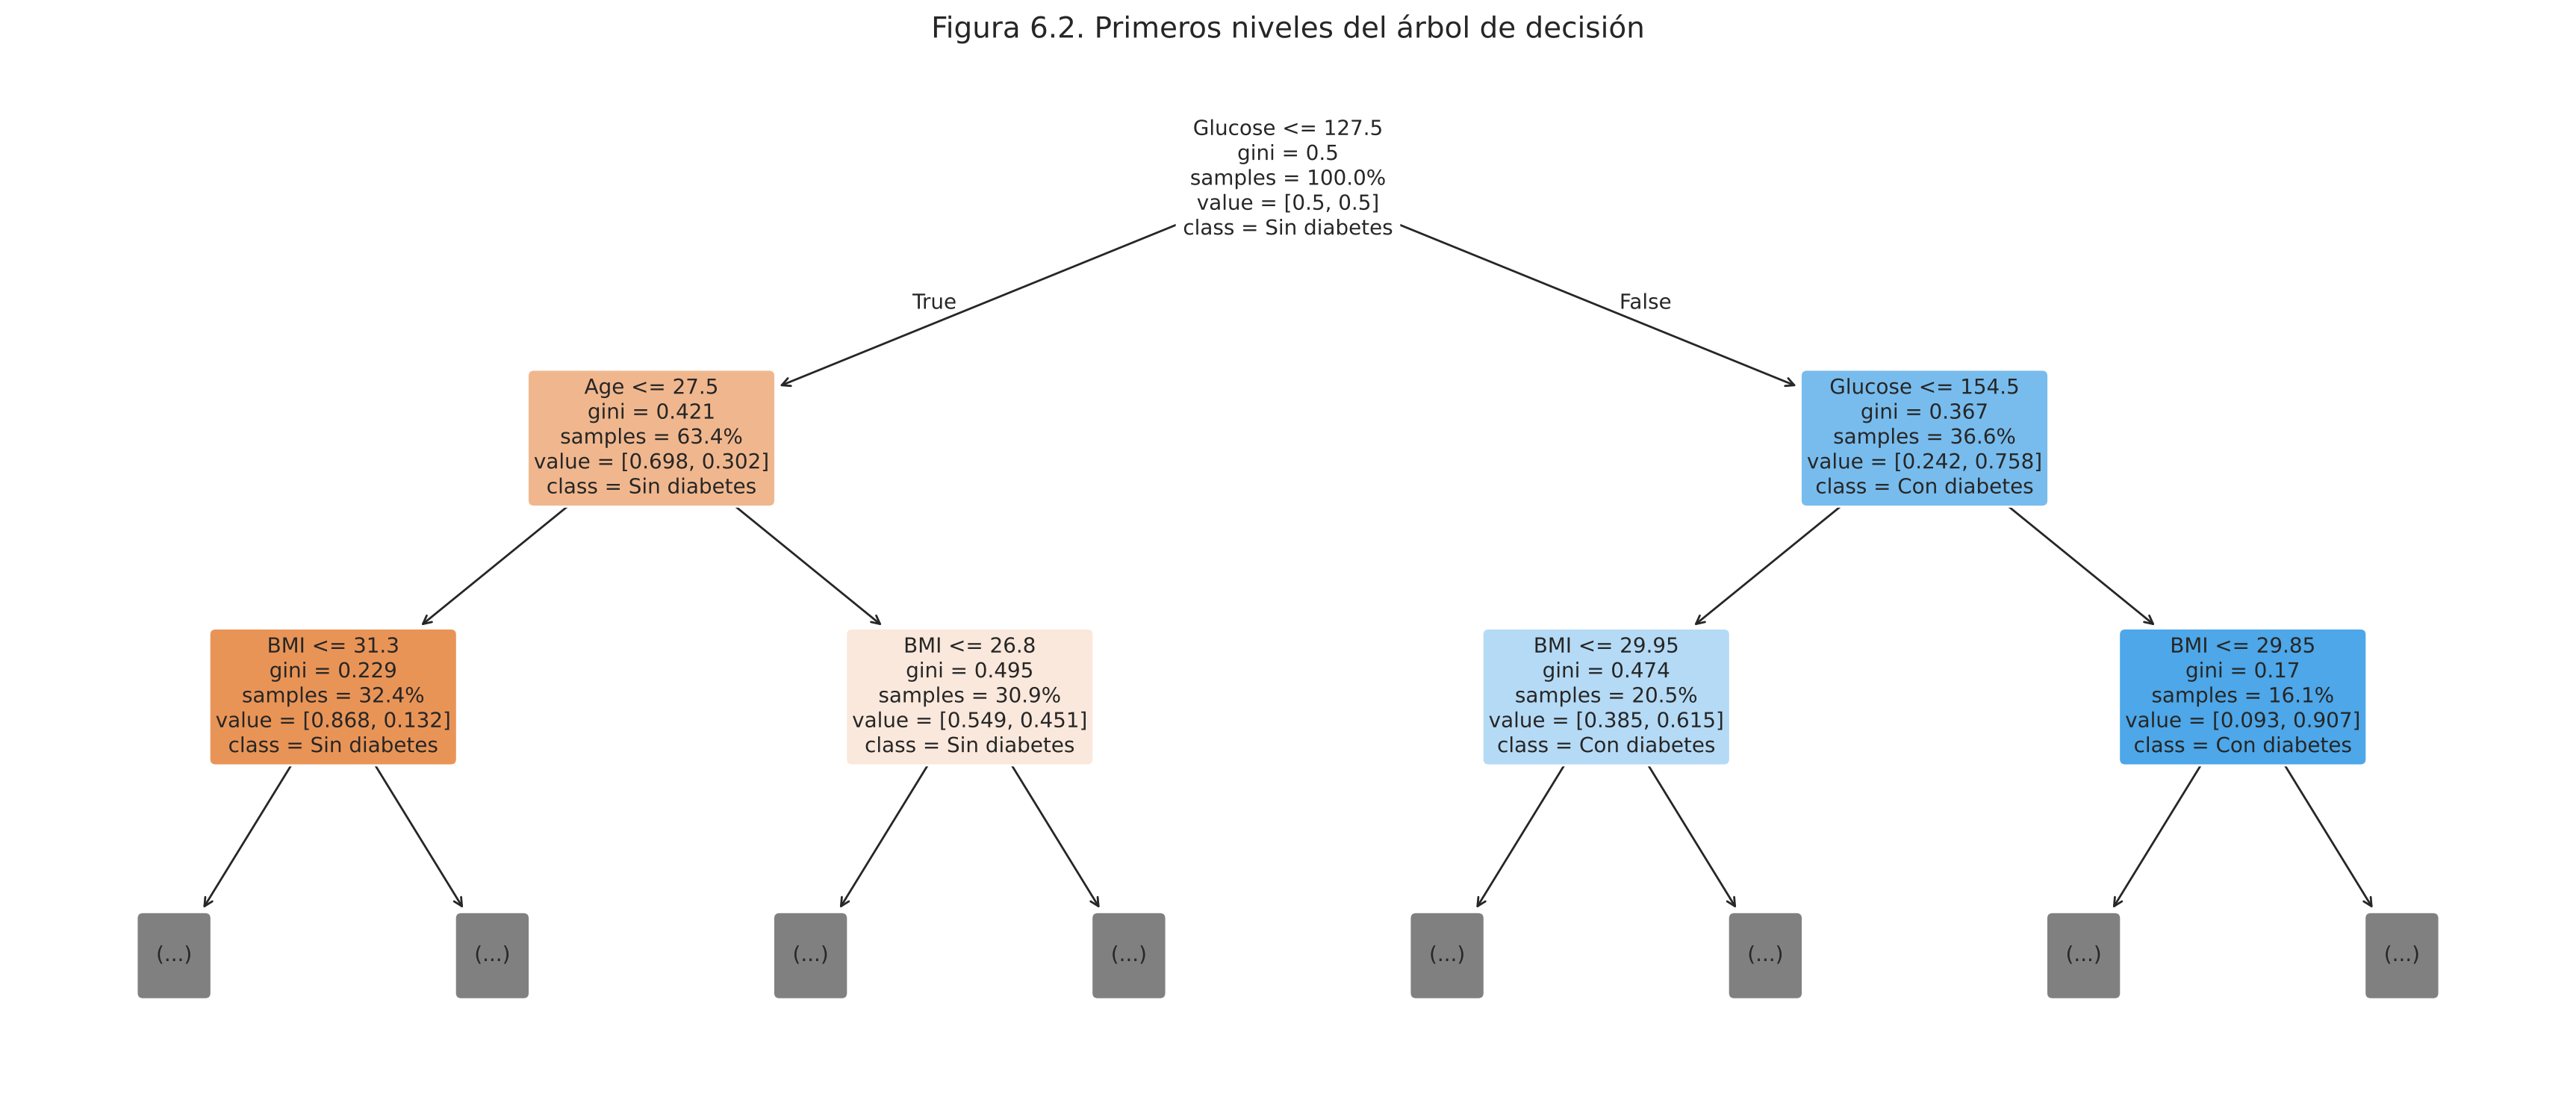

In [30]:
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 9))
plot_tree(modelos["Árbol de decisión"].named_steps["modelo"], feature_names=predictoras,
          class_names=["Sin diabetes", "Con diabetes"], filled=True, rounded=True,
          max_depth=2, fontsize=10, proportion=True)
plt.title("Figura 6.2. Primeros niveles del árbol de decisión", fontsize=14)
plt.show()

**Interpretación:** la figura muestra los dos primeros niveles del árbol (el modelo completo llega a profundidad 4). La primera división usa la glucosa (≤ 127.5 mg/dL). Por ejemplo, la rama de la derecha, con glucosa mayor que 154.5 mg/dL e IMC mayor que 29.85, contiene sobre todo pacientes con diabetes. En la rama izquierda, el árbol usa la edad (≤ 27.5 años) y luego el IMC. Las reglas son fáciles de explicar, lo que es la principal ventaja de este modelo.

*Nota de lectura:* `samples` indica el porcentaje de registros de entrenamiento que llega a cada nodo, y `value` muestra la proporción de cada clase **ponderada** por `class_weight="balanced"`; por eso la raíz aparece con 0.5 / 0.5 aunque los datos reales son 65/35.

## 7. Evaluación e interpretación de los modelos

Los modelos se evalúan sobre el **conjunto de prueba** (154 registros no usados en el entrenamiento) y se complementa con **validación cruzada** sobre el entrenamiento. Se reportan las siguientes métricas:

- **Accuracy:** proporción total de aciertos. Con clases desbalanceadas puede ser engañosa.
- **Precision (clase 1):** de las pacientes que el modelo marca con diabetes, qué proporción realmente la tiene. Una precision baja implica muchas falsas alarmas.
- **Recall o sensibilidad (clase 1):** de las pacientes que realmente tienen diabetes, qué proporción detecta el modelo. Es la **métrica prioritaria** en este problema, porque un falso negativo deja sin detectar un caso.
- **F1 (clase 1):** media armónica de precision y recall; resume el equilibrio entre ambas.
- **Especificidad (recall de la clase 0):** proporción de pacientes sin diabetes clasificadas correctamente.
- **F1 macro:** promedio del F1 de ambas clases, sin ponderar por su tamaño.
- **ROC-AUC:** capacidad del modelo para ordenar a las pacientes según su probabilidad de diabetes, independientemente del umbral de decisión (0.5 = azar, 1 = perfecto).

### 7.1 Métricas en el conjunto de prueba

Se incluye una **línea base** que predice siempre "sin diabetes", para comprobar que los modelos aportan algo más que la clase mayoritaria.

In [31]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

def metricas(y_real, y_pred, y_prob=None):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    res = {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision (1)": precision_score(y_real, y_pred, zero_division=0),
        "Recall / sensibilidad (1)": recall_score(y_real, y_pred, zero_division=0),
        "F1 (1)": f1_score(y_real, y_pred, zero_division=0),
        "Especificidad (recall 0)": tn / (tn + fp),
        "F1 macro": f1_score(y_real, y_pred, average="macro", zero_division=0),
    }
    res["ROC-AUC"] = roc_auc_score(y_real, y_prob) if y_prob is not None else np.nan
    return res

# Línea base: predecir siempre la clase mayoritaria (sin diabetes)
linea_base = np.zeros(len(y_test), dtype=int)

tabla_metricas = pd.DataFrame(
    {"Línea base (siempre 0)": metricas(y_test, linea_base),
     **{n: metricas(y_test, predicciones[n], probabilidades[n]) for n in modelos}}
).T
tabla_metricas.round(3)

,Accuracy,Precision (1),Recall / sensibilidad (1),F1 (1),Especificidad (recall 0),F1 macro,ROC-AUC
Línea base (siempre 0),0.649,0.000,0.000,0.000,1.00,0.394,NaN
Regresión logística,0.734,0.603,0.704,0.650,0.75,0.717,0.813
Árbol de decisión,0.714,0.561,0.852,0.676,0.64,0.710,0.798
Random forest,0.727,0.588,0.741,0.656,0.72,0.715,0.819


**Interpretación:**
- La línea base obtiene un *accuracy* de 0.649 sin detectar **ninguna** paciente con diabetes (recall = 0). Esto confirma que el *accuracy* no sirve por sí solo para comparar los modelos.
- Los tres modelos superan claramente la línea base. Sus *accuracy* son muy parecidos (entre 0.714 y 0.734), pero difieren en el tipo de error que cometen.
- El **árbol de decisión** tiene el **mayor recall** (0.852) y el mayor F1 de la clase 1 (0.676), pero la **menor especificidad** (0.64) y la menor precision (0.561): detecta más casos a costa de más falsas alarmas.
- La **regresión logística** tiene el mejor *accuracy* (0.734) y la mejor especificidad (0.75), pero el menor recall (0.704).
- El **random forest** queda en una posición intermedia en recall (0.741) y precision (0.588), y obtiene el **mayor ROC-AUC** (0.819), es decir, es el que mejor ordena a las pacientes por riesgo.

### 7.2 Resultados por clase

In [32]:
# Resultados por clase de cada modelo
reportes = []
for nombre in modelos:
    rep = pd.DataFrame(classification_report(
        y_test, predicciones[nombre], target_names=["Sin diabetes (0)", "Con diabetes (1)"],
        output_dict=True, zero_division=0)).T.loc[["Sin diabetes (0)", "Con diabetes (1)"]]
    rep.insert(0, "Modelo", nombre)
    reportes.append(rep)
reporte_por_clase = pd.concat(reportes).rename_axis("Clase").reset_index().set_index(["Modelo", "Clase"])
reporte_por_clase.round(3)

precision  recall  f1-score  support
Modelo              Clase                                                 
Regresión logística Sin diabetes (0)      0.824   0.750     0.785    100.0
                    Con diabetes (1)      0.603   0.704     0.650     54.0
Árbol de decisión   Sin diabetes (0)      0.889   0.640     0.744    100.0
                    Con diabetes (1)      0.561   0.852     0.676     54.0
Random forest       Sin diabetes (0)      0.837   0.720     0.774    100.0
                    Con diabetes (1)      0.588   0.741     0.656     54.0

**Interpretación:** los tres modelos clasifican mejor la clase 0 (F1 entre 0.744 y 0.785) que la clase 1 (F1 entre 0.650 y 0.676), lo cual es esperable porque la clase 1 es la minoritaria y se superpone con la clase 0 en la zona intermedia de glucosa (sección 5). En la clase 1, la precision de los tres modelos es moderada (0.561 a 0.603): aproximadamente 4 de cada 10 pacientes marcadas con diabetes no la tienen.

### 7.3 Matrices de confusión

Las filas son las clases reales y las columnas las clases predichas. La diagonal contiene los aciertos. Para este problema, la celda más importante es la inferior izquierda: **falsos negativos (FN)**, pacientes con diabetes que el modelo no detecta. La superior derecha son **falsos positivos (FP)**, falsas alarmas.

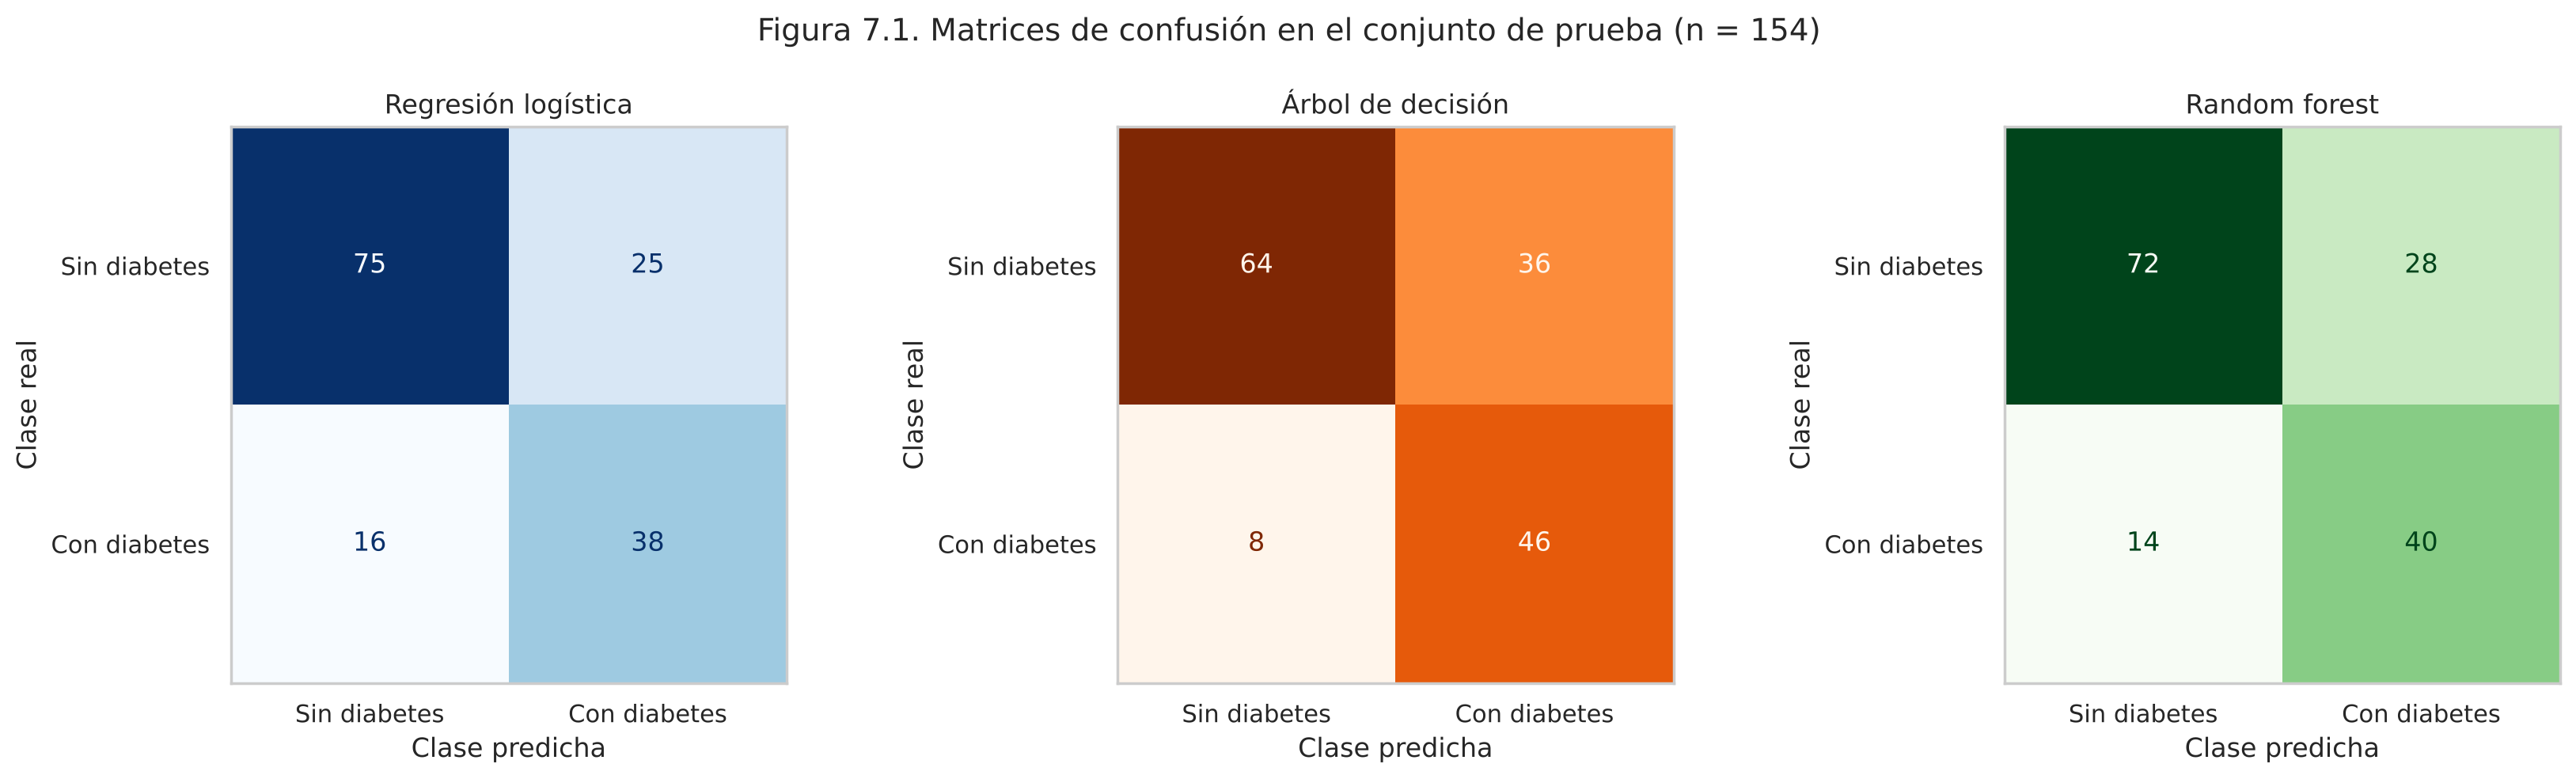

,VN (sano bien clasificado),FP (falsa alarma),FN (diabetes no detectada),VP (diabetes detectada),Aciertos,Errores
Modelo,,,,,,
Regresión logística,75,25,16,38,113,41
Árbol de decisión,64,36,8,46,110,44
Random forest,72,28,14,40,112,42


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, nombre, cmap in zip(axes, modelos, ["Blues", "Oranges", "Greens"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicciones[nombre], labels=[0, 1],
        display_labels=["Sin diabetes", "Con diabetes"], cmap=cmap, colorbar=False, ax=ax)
    ax.set(title=nombre, xlabel="Clase predicha", ylabel="Clase real")
    ax.grid(False)
fig.suptitle("Figura 7.1. Matrices de confusión en el conjunto de prueba (n = 154)", fontsize=14)
plt.tight_layout()
plt.show()

errores = []
for nombre in modelos:
    tn, fp, fn, tp = confusion_matrix(y_test, predicciones[nombre], labels=[0, 1]).ravel()
    errores.append({"Modelo": nombre, "VN (sano bien clasificado)": tn, "FP (falsa alarma)": fp,
                    "FN (diabetes no detectada)": fn, "VP (diabetes detectada)": tp,
                    "Aciertos": tn + tp, "Errores": fp + fn})
tabla_errores = pd.DataFrame(errores).set_index("Modelo")
tabla_errores

**Interpretación:**
- **Regresión logística:** 113 aciertos y 41 errores: 16 FN y 25 FP. Es el modelo que más casos de diabetes deja sin detectar.
- **Árbol de decisión:** 110 aciertos y 44 errores: solo 8 FN, pero 36 FP. Detecta 46 de las 54 pacientes con diabetes, la mayor cantidad, a cambio de generar 11 falsas alarmas más que la logística.
- **Random forest:** 112 aciertos y 42 errores: 14 FN y 28 FP.

El número total de errores es casi igual en los tres modelos (41 a 44); lo que cambia es **cómo se reparten**. Si el objetivo es usar el modelo como apoyo para la detección temprana, un FP implica una prueba confirmatoria adicional, mientras que un FN implica no detectar a una paciente con diabetes. Por eso se valora más reducir los FN, sin aceptar cualquier cantidad de FP.

### 7.4 Análisis de los errores más relevantes (falsos negativos)

Se comparan las medianas de las pacientes con diabetes que cada modelo detecta (VP) con las que no detecta (FN).

In [34]:
# ¿Cómo son las pacientes con diabetes que cada modelo no detecta (FN) frente a las detectadas (VP)?
es_positivo = (y_test == 1).to_numpy()
tablas_fn = []
for nombre in modelos:
    pos = X_test[es_positivo].copy()
    pos["Resultado"] = np.where(predicciones[nombre][es_positivo] == 1, "Detectadas (VP)", "No detectadas (FN)")
    resumen_fn = pos.groupby("Resultado")[["Glucose", "BMI", "Age", "DiabetesPedigreeFunction"]].median()
    resumen_fn["n"] = pos["Resultado"].value_counts()
    resumen_fn.insert(0, "Modelo", nombre)
    tablas_fn.append(resumen_fn.reset_index().set_index(["Modelo", "Resultado"]))
pd.concat(tablas_fn).round(2)

Glucose    BMI   Age  \
Modelo              Resultado                                  
Regresión logística Detectadas (VP)       147.5  35.25  38.0   
                    No detectadas (FN)    117.5  32.40  29.0   
Árbol de decisión   Detectadas (VP)       141.5  33.90  36.5   
                    No detectadas (FN)    111.0  32.15  26.5   
Random forest       Detectadas (VP)       146.5  34.60  38.0   
                    No detectadas (FN)    120.0  33.10  28.5   

                                        DiabetesPedigreeFunction   n  
Modelo              Resultado                                         
Regresión logística Detectadas (VP)                         0.45  38  
                    No detectadas (FN)                      0.29  16  
Árbol de decisión   Detectadas (VP)                         0.44  46  
                    No detectadas (FN)                      0.29   8  
Random forest       Detectadas (VP)                         0.45  40  
                    No detectadas (FN)                      0.29  14

**Interpretación:** en los tres modelos, las pacientes con diabetes **no detectadas** tienen una mediana de glucosa entre 111 y 120 mg/dL, frente a 141.5–147.5 mg/dL en las detectadas. También son más jóvenes (mediana de 26.5 a 29 años frente a 36.5–38) y tienen un `DiabetesPedigreeFunction` más bajo (0.29 frente a 0.44–0.45). Es decir, los falsos negativos corresponden a pacientes cuyo perfil se parece más al de las pacientes sin diabetes: la zona de superposición identificada en el EDA. Con solo estas 8 variables, estos casos son difíciles de distinguir para cualquiera de los tres modelos.

### 7.5 Comparación entre entrenamiento y prueba

Comparar el desempeño en entrenamiento y en prueba permite detectar **sobreajuste**: un modelo que rinde mucho mejor en los datos que ya vio que en datos nuevos está memorizando en lugar de generalizar.

In [35]:
# Comparación entrenamiento vs. prueba (sobreajuste)
filas = []
for nombre, m in modelos.items():
    pred_tr = m.predict(X_train)
    filas.append({"Modelo": nombre,
                  "Accuracy train": accuracy_score(y_train, pred_tr),
                  "Accuracy test": accuracy_score(y_test, predicciones[nombre]),
                  "Recall(1) train": recall_score(y_train, pred_tr),
                  "Recall(1) test": recall_score(y_test, predicciones[nombre]),
                  "F1(1) train": f1_score(y_train, pred_tr),
                  "F1(1) test": f1_score(y_test, predicciones[nombre])})
tabla_train_test = pd.DataFrame(filas).set_index("Modelo")
tabla_train_test["Brecha F1(1)"] = tabla_train_test["F1(1) train"] - tabla_train_test["F1(1) test"]
tabla_train_test.round(3)

,Accuracy train,Accuracy test,Recall(1) train,Recall(1) test,F1(1) train,F1(1) test,Brecha F1(1)
Modelo,,,,,,,
Regresión logística,0.759,0.734,0.710,0.704,0.673,0.650,0.023
Árbol de decisión,0.762,0.714,0.888,0.852,0.722,0.676,0.046
Random forest,0.886,0.727,0.916,0.741,0.848,0.656,0.193


**Interpretación:**
- **Regresión logística:** desempeño casi igual en entrenamiento y prueba (brecha de F1 de 0.023). Es el modelo más estable.
- **Árbol de decisión:** brecha moderada (0.046); limitar la profundidad a 4 evitó un sobreajuste fuerte.
- **Random forest:** brecha grande (F1 de 0.848 en entrenamiento frente a 0.656 en prueba; 0.193 de diferencia). Ajusta muy bien los datos de entrenamiento, lo que es habitual en este tipo de modelo. Aun así, su desempeño en prueba es comparable al de los otros modelos, por lo que la brecha no se traduce en un peor resultado en datos nuevos, pero sí indica margen para regularizarlo (por ejemplo, limitando la profundidad de los árboles) en el tercer corte.

### 7.6 Validación cruzada

Una sola división entrenamiento/prueba puede favorecer por azar a un modelo. La **validación cruzada estratificada de 5 pliegues** entrena y evalúa cada modelo cinco veces sobre distintas particiones del conjunto de entrenamiento, y reporta la media y la desviación estándar de cada métrica. Una desviación pequeña indica resultados estables. El conjunto de prueba no participa en este paso.

In [36]:
# Validación cruzada estratificada de 5 pliegues sobre el conjunto de ENTRENAMIENTO
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
metricas_cv = {"accuracy": "accuracy", "recall": "recall", "precision": "precision",
               "f1": "f1", "roc_auc": "roc_auc"}

filas = []
for nombre, m in modelos.items():
    res = cross_validate(clone(m), X_train, y_train, cv=cv, scoring=metricas_cv)
    fila = {"Modelo": nombre}
    for k in metricas_cv:
        fila[f"{k} (media)"] = res[f"test_{k}"].mean()
        fila[f"{k} (desv.)"] = res[f"test_{k}"].std()
    filas.append(fila)
tabla_cv = pd.DataFrame(filas).set_index("Modelo")
tabla_cv.round(3)

,accuracy (media),accuracy (desv.),recall (media),recall (desv.),precision (media),precision (desv.),f1 (media),f1 (desv.),roc_auc (media),roc_auc (desv.)
Modelo,,,,,,,,,,
Regresión logística,0.762,0.011,0.701,0.039,0.649,0.026,0.672,0.013,0.844,0.016
Árbol de decisión,0.697,0.040,0.734,0.107,0.554,0.048,0.626,0.048,0.783,0.028
Random forest,0.764,0.012,0.743,0.034,0.640,0.023,0.687,0.015,0.837,0.021


**Interpretación:** la validación cruzada **matiza** los resultados de la prueba:
- El **árbol de decisión**, que tuvo el mejor recall en prueba (0.852), obtiene en validación cruzada un recall medio de 0.734 con una desviación alta (0.107), y el F1 (0.626) y el ROC-AUC (0.783) más bajos de los tres. Su buen resultado en prueba parece depender en parte de la partición específica, y el modelo es el **menos estable**.
- El **random forest** obtiene el **mayor recall medio** (0.743, desviación 0.034) y el **mayor F1 medio** (0.687), con baja variabilidad.
- La **regresión logística** tiene el mayor ROC-AUC medio (0.844, frente a 0.837 del random forest) y una variabilidad baja, similar a la del random forest, pero el recall medio más bajo (0.701).

La validación cruzada aporta así una estimación más confiable que una sola partición y muestra que la ventaja del árbol en prueba no se sostiene.

### 7.7 Curvas ROC

La curva ROC muestra, para todos los umbrales de decisión posibles, la relación entre la tasa de verdaderos positivos (recall) y la tasa de falsos positivos. Cuanto más se acerca la curva a la esquina superior izquierda, mejor discrimina el modelo.

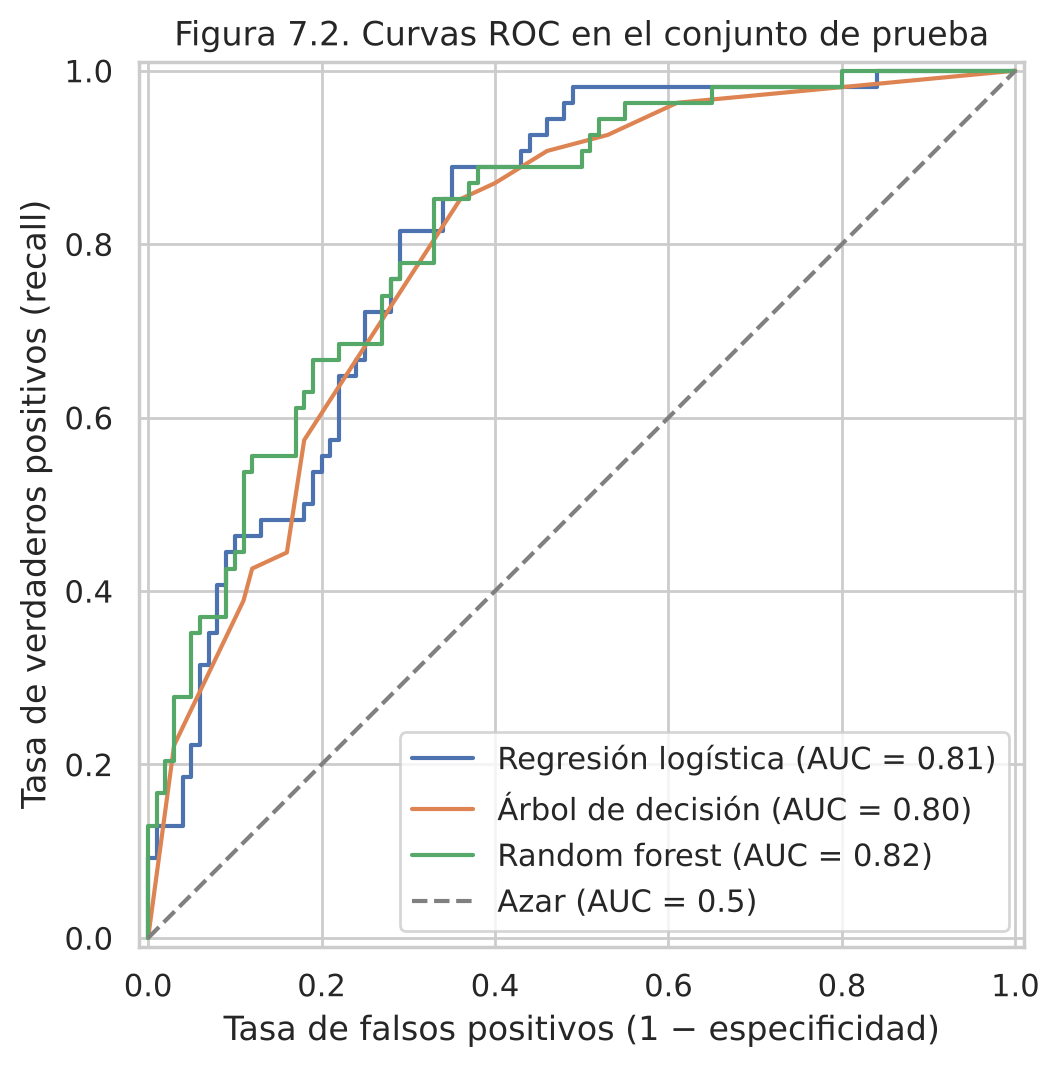

In [37]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nombre in modelos:
    RocCurveDisplay.from_predictions(y_test, probabilidades[nombre], name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], ls="--", color="gray", label="Azar (AUC = 0.5)")
ax.set(title="Figura 7.2. Curvas ROC en el conjunto de prueba",
       xlabel="Tasa de falsos positivos (1 − especificidad)", ylabel="Tasa de verdaderos positivos (recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretación:** las tres curvas están muy por encima de la diagonal del azar y son bastante parecidas (AUC entre 0.80 y 0.82). Las curvas indican que los modelos podrían alcanzar un recall más alto si se bajara el umbral de 0.5, a cambio de más falsos positivos. Ajustar el umbral según el costo de cada error queda como trabajo para el tercer corte, ya que esta entrega no incluye optimización.

### 7.8 Comparación final y selección preliminar del modelo

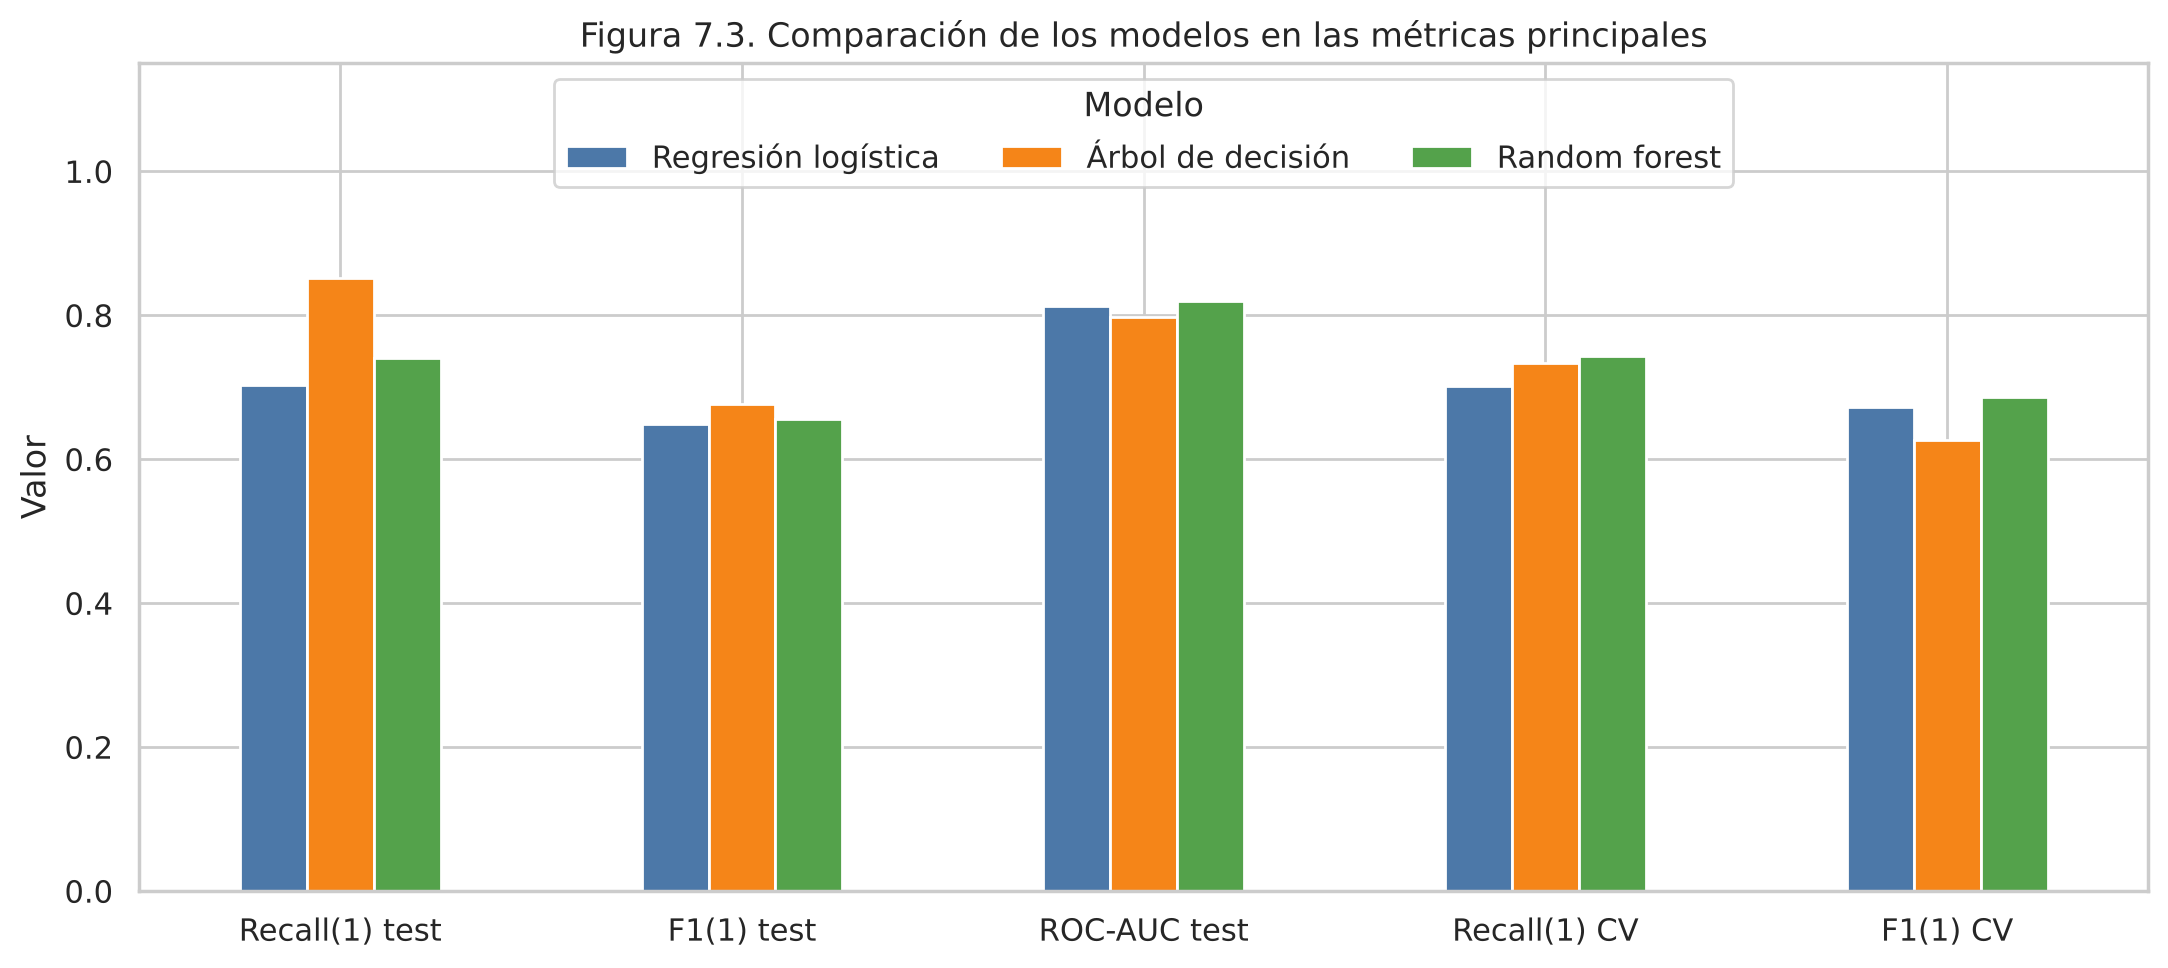

,Recall(1) test,Precision(1) test,F1(1) test,ROC-AUC test,FN test,FP test,Recall(1) CV,F1(1) CV,ROC-AUC CV,Brecha F1 train-test
Regresión logística,0.704,0.603,0.650,0.813,16,25,0.701,0.672,0.844,0.023
Árbol de decisión,0.852,0.561,0.676,0.798,8,36,0.734,0.626,0.783,0.046
Random forest,0.741,0.588,0.656,0.819,14,28,0.743,0.687,0.837,0.193


In [38]:
# Resumen comparativo de las evidencias
resumen = pd.DataFrame({
    "Recall(1) test": tabla_metricas.loc[list(modelos), "Recall / sensibilidad (1)"],
    "Precision(1) test": tabla_metricas.loc[list(modelos), "Precision (1)"],
    "F1(1) test": tabla_metricas.loc[list(modelos), "F1 (1)"],
    "ROC-AUC test": tabla_metricas.loc[list(modelos), "ROC-AUC"],
    "FN test": tabla_errores["FN (diabetes no detectada)"],
    "FP test": tabla_errores["FP (falsa alarma)"],
    "Recall(1) CV": tabla_cv["recall (media)"],
    "F1(1) CV": tabla_cv["f1 (media)"],
    "ROC-AUC CV": tabla_cv["roc_auc (media)"],
    "Brecha F1 train-test": tabla_train_test["Brecha F1(1)"],
})
ax = resumen[["Recall(1) test", "F1(1) test", "ROC-AUC test", "Recall(1) CV", "F1(1) CV"]].T.plot(
    kind="bar", figsize=(11, 5), color=["#4C78A8", "#F58518", "#54A24B"], rot=0)
ax.set(title="Figura 7.3. Comparación de los modelos en las métricas principales", ylabel="Valor", ylim=(0, 1.15))
ax.legend(title="Modelo", loc="upper center", ncol=3)
plt.tight_layout()
plt.show()
resumen.round(3)

**Selección preliminar: random forest**, con la regresión logística como modelo de referencia.

No se elige por *accuracy* (los tres están entre 0.714 y 0.734). Se consideran varias evidencias, dando prioridad a detectar los casos de diabetes:

1. **Recall de la clase 1 en validación cruzada:** el random forest es el mejor (0.743) y el más estable entre los modelos basados en árboles (desviación 0.034 frente a 0.107 del árbol).
2. **F1 de la clase 1 en validación cruzada:** el random forest es el mejor (0.687), es decir, logra el mejor equilibrio entre detectar casos y evitar falsas alarmas.
3. **ROC-AUC:** el random forest tiene el mayor AUC en prueba (0.819) y el segundo en validación cruzada (0.837, muy cerca de 0.844 de la logística).
4. **Matriz de confusión:** deja sin detectar 14 casos, frente a 16 de la logística, con 28 falsas alarmas, frente a 36 del árbol.

**Por qué no el árbol de decisión:** aunque tiene el mejor recall en prueba (8 FN), ese resultado no se confirma en validación cruzada, donde es el modelo más inestable y con el F1 y el AUC más bajos; además, genera el mayor número de falsas alarmas.

**Por qué conservar la regresión logística como referencia:** es la más estable (menor brecha entre entrenamiento y prueba), tiene el mejor AUC en validación cruzada y sus coeficientes son fáciles de interpretar. Su desventaja es que detecta menos casos de diabetes.

**Precauciones:** las diferencias entre los modelos son pequeñas (por ejemplo, 2 FN entre el random forest y la logística en un conjunto de prueba de 54 positivas), y el random forest muestra sobreajuste en entrenamiento. La selección es **preliminar** y se revisará en el tercer corte.

## 8. Conclusiones del segundo avance

**¿Cuáles fueron los principales hallazgos del EDA?**
La variable objetivo presenta un desbalance moderado (65.1 % sin diabetes y 34.9 % con diabetes). `Glucose` es la variable más asociada al diagnóstico: su mediana pasa de 107 a 140 mg/dL entre grupos, su correlación con `Outcome` es de 0.49 y la proporción de diabetes crece de forma sostenida con la glucosa (de 8.6 % con valores ≤ 100 mg/dL a 83.6 % entre 176 y 200 mg/dL). `BMI` y `Age` le siguen en importancia; la relación con la edad no es monótona. Las clases se superponen en todas las variables, no hay multicolinealidad severa (correlación máxima entre predictoras de 0.65) y los valores atípicos son plausibles y frecuentes en la clase positiva, por lo que se conservaron. Además, se corrigió la imputación del primer avance para evitar fuga de información.

**¿Qué modelo produjo los resultados más adecuados?**
De forma preliminar, el **random forest**, con la regresión logística como modelo de referencia.

**¿Qué evidencias respaldan esa selección?**
En validación cruzada, el random forest obtuvo el mayor recall de la clase 1 (0.743) y el mayor F1 (0.687), con baja variabilidad. En prueba alcanzó el mayor ROC-AUC (0.819) y dejó sin detectar 14 de 54 pacientes con diabetes (frente a 16 de la regresión logística), con 28 falsas alarmas (frente a 36 del árbol de decisión). El árbol tuvo el mejor recall en prueba (0.852), pero la validación cruzada mostró que ese resultado es inestable (desviación de 0.107) y fue el modelo con menor F1 y AUC. La selección no se basó en el *accuracy*, que fue similar en los tres modelos (0.714 a 0.734).

**¿Qué errores o limitaciones se identificaron?**
- Los tres modelos cometen entre 41 y 44 errores sobre 154 casos. Los falsos negativos corresponden a pacientes con glucosa intermedia (mediana de 111 a 120 mg/dL) y más jóvenes, cuyo perfil se superpone con el de pacientes sin diabetes.
- La precision de la clase 1 es moderada (0.561 a 0.603): alrededor de 4 de cada 10 alertas son falsas alarmas.
- El random forest muestra sobreajuste (F1 de 0.848 en entrenamiento frente a 0.656 en prueba).
- `Insulin` y `SkinThickness` tienen un alto porcentaje de valores imputados (48.7 % y 29.6 %), lo que limita la información que aportan.
- El dataset es pequeño (768 registros) y corresponde a una población específica (mujeres de herencia Pima), por lo que los resultados no se pueden generalizar sin validación externa.
- Las diferencias entre modelos son pequeñas y provienen de una sola partición de prueba.

**Pendiente para el tercer corte:** ajustar hiperparámetros y el umbral de decisión con validación cruzada, regularizar el random forest, evaluar transformaciones para variables asimétricas e indicadores de valores faltantes, y redactar el artículo final.

## 9. Uso de inteligencia artificial

En este avance se utilizó Claude (Anthropic) como apoyo para estructurar el notebook, proponer y escribir el código, revisar la coherencia entre resultados e interpretaciones y redactar borradores de texto. Todas las cifras de las interpretaciones se tomaron de las salidas de este notebook después de ejecutarlo completo. La declaración detallada —herramienta, propósito, prompts, problemas identificados, ajustes realizados y decisión final— se presenta en el informe PDF, en la sección *Declaración y evaluación del uso de inteligencia artificial*.

## 10. Tercer corte: revisión, optimización y preparación del modelo para Streamlit

Esta sección corresponde a la Actividad 1 del tercer corte. Parte del modelo seleccionado en el segundo avance (random forest), revisa su calidad con la *Ficha de revisión de resultados* del curso, registra los ajustes realizados, compara los resultados **anteriores y posteriores** y guarda el pipeline final que carga la aplicación.

### 10.1 Revisión del proceso (ficha de diagnóstico)

| Paso de la ficha | Revisión | Dónde se evidencia |
|---|---|---|
| **1. Datos** | Sin nulos explícitos ni duplicados; ceros imposibles tratados como faltantes; atípicos analizados y conservados (no borrados por reflejo); ninguna predictora se deriva de `Outcome`. | Secciones 3 y 4 |
| **2. Separación** | División 80/20 **estratificada** antes de imputar o escalar; el conjunto de prueba no se usa para ajustar nada. | Sección 6.2 |
| **3. Pipeline** | Imputación (y escalamiento en la logística) dentro de un `Pipeline`, ajustados solo con entrenamiento. Faltaba **guardar el pipeline completo**: se hace en la sección 10.6. | Secciones 4.5, 6.3 y 10.6 |
| **4. Evaluación** | Línea base, matriz de confusión, precision, recall y F1 por clase, y validación cruzada con media y desviación. | Sección 7 |
| **5. Ajuste** | Pendiente en el segundo avance: los hiperparámetros eran fijos. Se realiza en esta sección con entrenamiento + validación cruzada, evaluando **una sola vez** en prueba. | Secciones 10.3 a 10.5 |

### 10.2 Señales identificadas en el modelo del segundo avance

- **Sobreajuste** (entrenamiento alto + validación baja): el random forest obtuvo un F1 de la clase 1 de 0.848 en entrenamiento frente a 0.656 en prueba (brecha de 0.193). La ficha recomienda reducir la complejidad, regularizar o limitar la profundidad.
- **Métrica por debajo de 0.70:** el *accuracy* (0.727) y el recall de la clase 1 (0.741) superaban 0.70, pero el F1 de la clase 1 (0.656) y la precision (0.588) no. Como el enunciado indica que el 70 % es una señal de revisión, se revisa el modelo antes de integrarlo.
- **Falsos negativos:** el modelo dejaba sin detectar 14 de las 54 pacientes con diabetes del conjunto de prueba. Al ser el error más costoso del problema, se evalúa ajustar el umbral de decisión.
- **Inestabilidad:** no se observó en el random forest (desviación del recall en validación cruzada de 0.034).
- **Métrica engañosa:** no aplica; el recall de la clase positiva no es bajo frente al *accuracy*.

### 10.3 Ajuste 1: regularización del random forest con búsqueda de hiperparámetros

Se buscan hiperparámetros que **limiten la complejidad** de los árboles: profundidad máxima (`max_depth`), mínimo de registros por hoja (`min_samples_leaf`) y proporción de variables por división (`max_features`). La búsqueda usa **solo el conjunto de entrenamiento** con validación cruzada estratificada de 5 pliegues (la misma partición `cv` de la sección 7.6) y selecciona la combinación con mayor F1 de la clase 1. El conjunto de prueba no interviene.

In [39]:
from sklearn.model_selection import GridSearchCV

rf_base = modelos["Random forest"]          # modelo del segundo avance (ya entrenado)

rejilla = {
    "modelo__max_depth": [3, 4, 5, 6, 8, None],
    "modelo__min_samples_leaf": [5, 10, 20, 30],
    "modelo__max_features": ["sqrt", 0.5],
}
busqueda = GridSearchCV(
    clone(rf_base), rejilla, cv=cv,
    scoring={"f1": "f1", "recall": "recall", "precision": "precision", "roc_auc": "roc_auc", "accuracy": "accuracy"},
    refit="f1", return_train_score=True, n_jobs=-1)
busqueda.fit(X_train, y_train)

print("Combinaciones evaluadas:", len(busqueda.cv_results_["params"]))
print("Mejores hiperparámetros:", busqueda.best_params_)

res = pd.DataFrame(busqueda.cv_results_)
tabla_busqueda = res.sort_values("mean_test_f1", ascending=False)[[
    "param_modelo__max_depth", "param_modelo__min_samples_leaf", "param_modelo__max_features",
    "mean_test_f1", "std_test_f1", "mean_train_f1", "mean_test_recall", "mean_test_precision", "mean_test_roc_auc"]].head(5)
tabla_busqueda.columns = ["max_depth", "min_samples_leaf", "max_features", "F1 CV (media)", "F1 CV (desv.)",
                          "F1 entrenamiento", "Recall CV", "Precision CV", "ROC-AUC CV"]
tabla_busqueda.round(3)

Combinaciones evaluadas: 48
Mejores hiperparámetros: {'modelo__max_depth': 8, 'modelo__max_features': 0.5, 'modelo__min_samples_leaf': 10}


,max_depth,min_samples_leaf,max_features,F1 CV (media),F1 CV (desv.),F1 entrenamiento,Recall CV,Precision CV,ROC-AUC CV
37,8,10,0.5,0.704,0.020,0.782,0.766,0.653,0.838
45,None,10,0.5,0.703,0.018,0.783,0.762,0.654,0.838
8,4,5,sqrt,0.702,0.017,0.769,0.776,0.642,0.841
22,5,20,0.5,0.702,0.011,0.753,0.757,0.656,0.839
46,None,20,0.5,0.700,0.013,0.754,0.752,0.656,0.840


**Interpretación:** se evaluaron 48 combinaciones. La mejor usa `max_depth=8`, `min_samples_leaf=10` y `max_features=0.5`, con un F1 medio en validación cruzada de 0.704 (desviación 0.020), frente a 0.687 del modelo del segundo avance. Al exigir al menos 10 registros por hoja (antes 5) y limitar la profundidad, el F1 en los pliegues de entrenamiento baja a 0.782, es decir, el modelo memoriza menos. Las cinco mejores combinaciones tienen un F1 casi idéntico (0.700 a 0.704), lo que indica que el resultado no depende de una configuración muy específica.

### 10.4 Ajuste 2: umbral de decisión

Por defecto, el modelo clasifica como "con diabetes" cuando la probabilidad estimada es de al menos 0.50. Como el error más costoso es el falso negativo, se evalúa un umbral menor. Para no usar el conjunto de prueba en esta decisión, el umbral se elige con las **probabilidades fuera de pliegue** del conjunto de entrenamiento (cada registro es predicho por un modelo que no lo vio).

**Regla definida antes de mirar la prueba:** elegir el umbral **más alto** que alcance un recall de la clase 1 de al menos **0.80** en validación cruzada. Así se garantiza una sensibilidad mínima con la menor cantidad posible de falsas alarmas.

Umbral seleccionado: 0.40


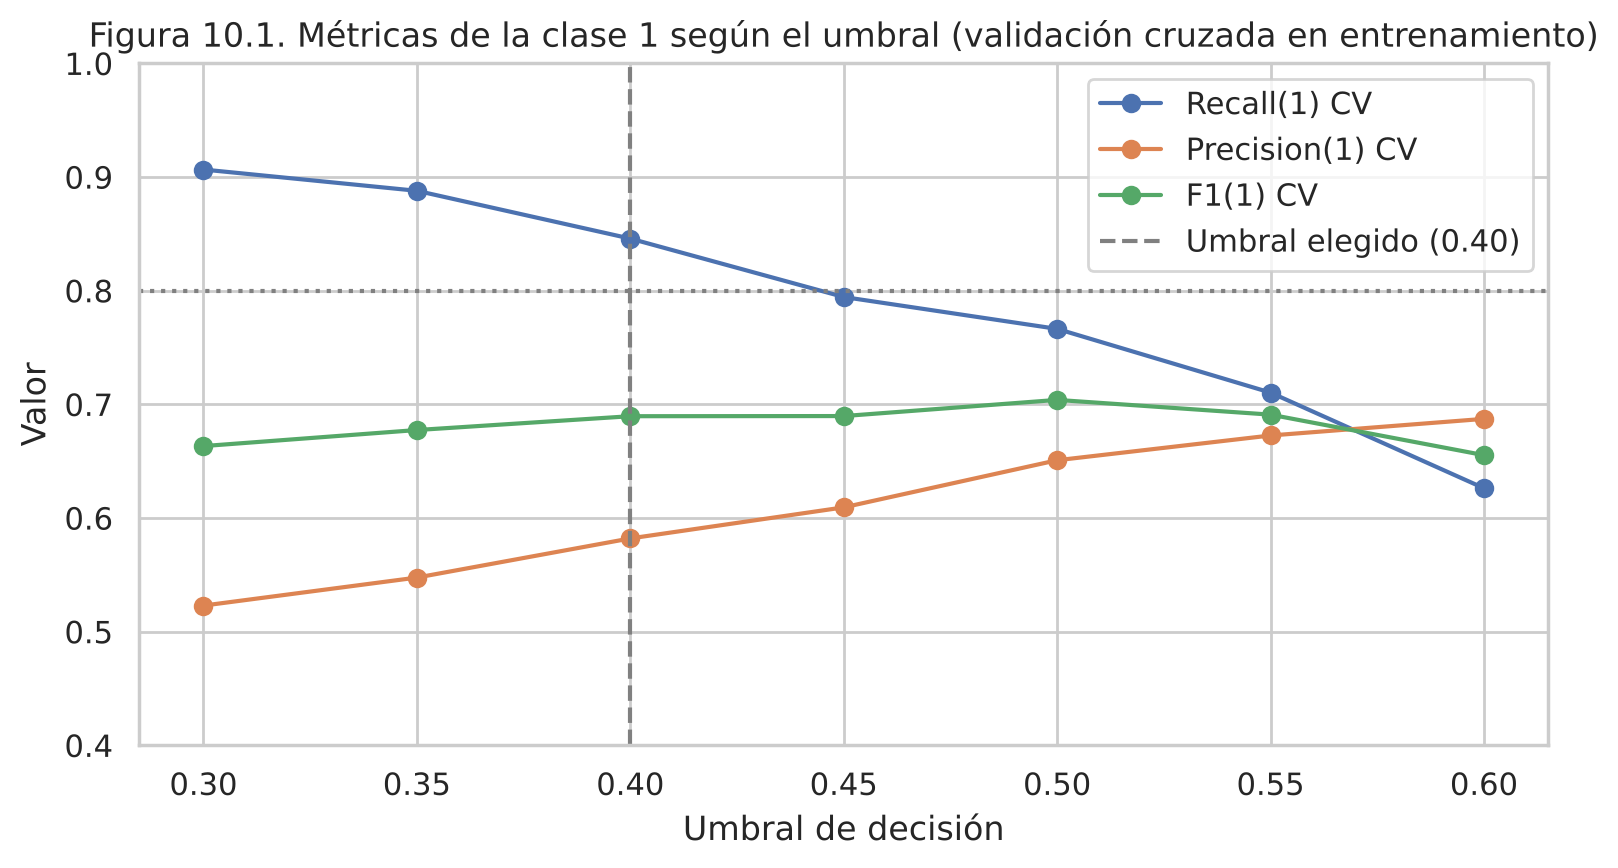

,Recall(1) CV,Precision(1) CV,F1(1) CV,Accuracy CV
umbral,,,,
0.30,0.907,0.523,0.663,0.679
0.35,0.888,0.548,0.677,0.705
0.40,0.846,0.582,0.690,0.735
0.45,0.794,0.609,0.690,0.751
0.50,0.766,0.651,0.704,0.775
0.55,0.710,0.673,0.691,0.779
0.60,0.626,0.687,0.655,0.770


In [40]:
from sklearn.model_selection import cross_val_predict

rf_opt = busqueda.best_estimator_
prob_cv = cross_val_predict(clone(rf_opt), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

filas = []
for u in np.arange(0.30, 0.61, 0.05).round(2):
    pred_u = (prob_cv >= u).astype(int)
    filas.append({"umbral": u,
                  "Recall(1) CV": recall_score(y_train, pred_u),
                  "Precision(1) CV": precision_score(y_train, pred_u),
                  "F1(1) CV": f1_score(y_train, pred_u),
                  "Accuracy CV": accuracy_score(y_train, pred_u)})
tabla_umbral = pd.DataFrame(filas).set_index("umbral")

RECALL_MINIMO = 0.80
UMBRAL = float(tabla_umbral[tabla_umbral["Recall(1) CV"] >= RECALL_MINIMO].index.max())
print(f"Umbral seleccionado: {UMBRAL:.2f}")

ax = tabla_umbral[["Recall(1) CV", "Precision(1) CV", "F1(1) CV"]].plot(marker="o", figsize=(8, 4.5))
ax.axvline(UMBRAL, ls="--", color="gray", label=f"Umbral elegido ({UMBRAL:.2f})")
ax.axhline(RECALL_MINIMO, ls=":", color="gray")
ax.set(title="Figura 10.1. Métricas de la clase 1 según el umbral (validación cruzada en entrenamiento)",
       xlabel="Umbral de decisión", ylabel="Valor", ylim=(0.4, 1))
ax.legend()
plt.tight_layout()
plt.show()
tabla_umbral.round(3)

**Interpretación:** al bajar el umbral aumenta el recall y disminuye la precision, como era de esperar. Con el umbral por defecto (0.50), el recall en validación cruzada es de 0.766; con 0.45 es de 0.794, todavía por debajo del mínimo fijado. El umbral más alto que cumple la regla es **0.40**, con un recall de 0.846, una precision de 0.582 y un F1 de 0.690. El costo es claro: el *accuracy* en validación cruzada baja de 0.775 a 0.735 y habrá más falsas alarmas. Se acepta ese intercambio porque en este problema una falsa alarma lleva a una prueba confirmatoria, mientras que un falso negativo deja un caso sin detectar.

### 10.5 Evaluación final en prueba: comparación antes y después

El modelo final se construye con `FixedThresholdClassifier`, que envuelve el pipeline optimizado y aplica el umbral elegido al predecir. Se entrena con el conjunto de entrenamiento y se evalúa **una sola vez** en el conjunto de prueba, junto con el modelo del segundo avance para comparar.

In [41]:
from sklearn.model_selection import FixedThresholdClassifier

modelo_final = FixedThresholdClassifier(clone(rf_opt), threshold=UMBRAL, response_method="predict_proba")
modelo_final.fit(X_train, y_train)

pred_final = modelo_final.predict(X_test)
prob_final = modelo_final.predict_proba(X_test)[:, 1]
pred_opt_05 = rf_opt.predict(X_test)            # modelo optimizado con el umbral por defecto (paso intermedio)

def fila_comparacion(nombre, modelo, pred_test, prob_test):
    pred_tr = modelo.predict(X_train)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_test, labels=[0, 1]).ravel()
    return {"Modelo": nombre,
            "Accuracy": accuracy_score(y_test, pred_test),
            "Precision (1)": precision_score(y_test, pred_test),
            "Recall (1)": recall_score(y_test, pred_test),
            "F1 (1)": f1_score(y_test, pred_test),
            "Especificidad": tn / (tn + fp),
            "ROC-AUC": roc_auc_score(y_test, prob_test),
            "FN": fn, "FP": fp,
            "F1(1) entrenamiento": f1_score(y_train, pred_tr),
            "Brecha F1": f1_score(y_train, pred_tr) - f1_score(y_test, pred_test)}

comparacion_final = pd.DataFrame([
    fila_comparacion("Antes: random forest del segundo avance", rf_base, predicciones["Random forest"], probabilidades["Random forest"]),
    fila_comparacion("Paso 1: hiperparámetros ajustados (umbral 0.50)", rf_opt, pred_opt_05, rf_opt.predict_proba(X_test)[:, 1]),
    fila_comparacion(f"Después: modelo final (umbral {UMBRAL:.2f})", modelo_final, pred_final, prob_final),
]).set_index("Modelo")
comparacion_final.round(3)

,Accuracy,Precision (1),Recall (1),F1 (1),Especificidad,ROC-AUC,FN,FP,F1(1) entrenamiento,Brecha F1
Modelo,,,,,,,,,,
Antes: random forest del segundo avance,0.727,0.588,0.741,0.656,0.72,0.819,14,28,0.848,0.193
Paso 1: hiperparámetros ajustados (umbral 0.50),0.753,0.625,0.741,0.678,0.76,0.830,14,24,0.784,0.106
Después: modelo final (umbral 0.40),0.727,0.575,0.852,0.687,0.66,0.830,8,34,0.767,0.081


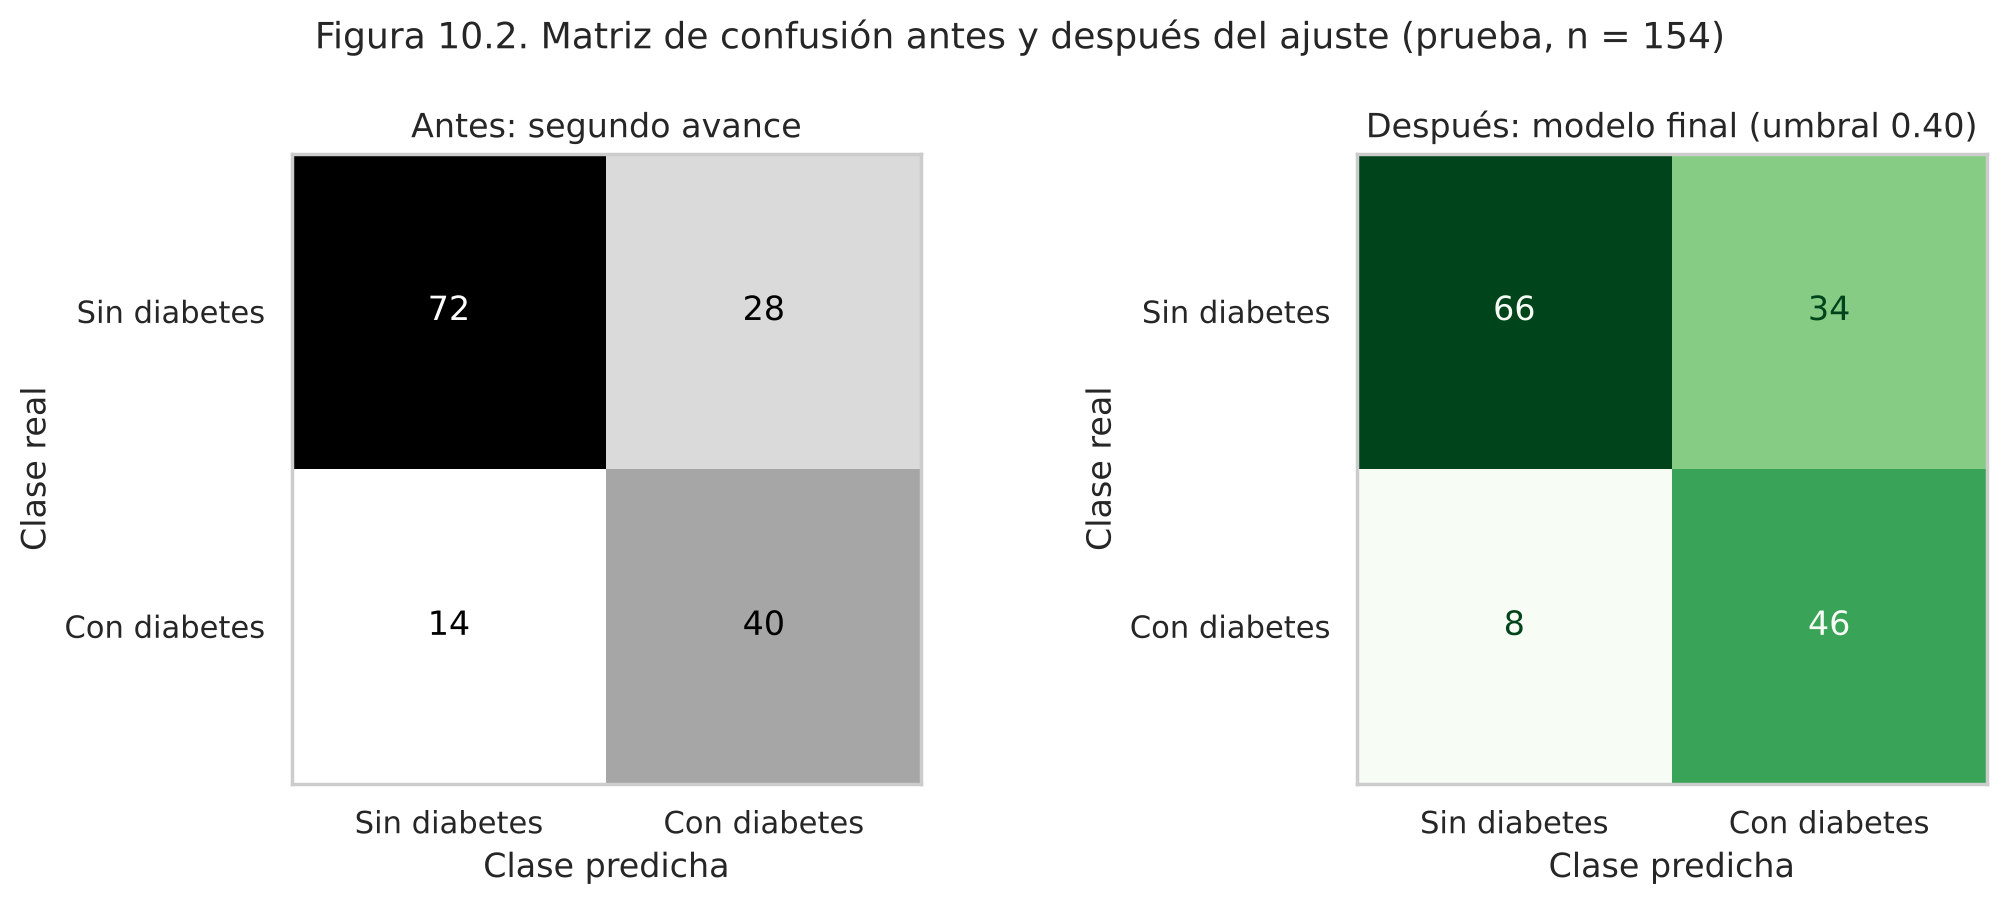

                  precision    recall  f1-score   support

Sin diabetes (0)      0.892     0.660     0.759       100
Con diabetes (1)      0.575     0.852     0.687        54

        accuracy                          0.727       154
       macro avg      0.733     0.756     0.723       154
    weighted avg      0.781     0.727     0.733       154



In [42]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, pred, titulo, cmap in [
        (axes[0], predicciones["Random forest"], "Antes: segundo avance", "Greys"),
        (axes[1], pred_final, f"Después: modelo final (umbral {UMBRAL:.2f})", "Greens")]:
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1],
        display_labels=["Sin diabetes", "Con diabetes"], cmap=cmap, colorbar=False, ax=ax)
    ax.set(title=titulo, xlabel="Clase predicha", ylabel="Clase real")
    ax.grid(False)
fig.suptitle("Figura 10.2. Matriz de confusión antes y después del ajuste (prueba, n = 154)", fontsize=13)
plt.tight_layout()
plt.show()

print(classification_report(y_test, pred_final, target_names=["Sin diabetes (0)", "Con diabetes (1)"], digits=3))

**Interpretación (antes y después, en prueba):**
- **Sobreajuste:** la brecha de F1 entre entrenamiento y prueba bajó de 0.193 a 0.081. La regularización corrigió la señal identificada en 10.2.
- **Paso 1 (hiperparámetros):** con el umbral de 0.50, el modelo ajustado mejora el *accuracy* (0.727 → 0.753), la precision (0.588 → 0.625), el F1 (0.656 → 0.678) y el ROC-AUC (0.819 → 0.830) con el mismo recall (0.741): reduce las falsas alarmas de 28 a 24 sin perder casos detectados.
- **Modelo final (umbral 0.40):** el recall de la clase 1 sube de 0.741 a **0.852** y los falsos negativos bajan de **14 a 8** (se detectan 46 de las 54 pacientes con diabetes). El F1 sube de 0.656 a 0.687 y el *accuracy* se mantiene en 0.727.
- **Costo del ajuste:** las falsas alarmas aumentan de 28 a 34, la especificidad baja de 0.72 a 0.66 y la precision queda en 0.575 (antes 0.588): de cada 10 pacientes que el modelo marca con riesgo, aproximadamente 4 no tienen diabetes.
- **Frente a la señal del 70 %:** el *accuracy* (0.727) y la métrica principal del proyecto, el recall de la clase 1 (0.852), superan 0.70. El F1 de la clase 1 (0.687) y la precision (0.575) siguen por debajo, lo que se declara como limitación del modelo.

In [43]:
# Estabilidad del modelo final: validación cruzada (entrenamiento) antes y después
filas = []
for nombre, m in [("Antes: random forest del segundo avance", rf_base),
                  (f"Después: modelo final (umbral {UMBRAL:.2f})", modelo_final)]:
    r = cross_validate(clone(m), X_train, y_train, cv=cv, scoring=metricas_cv)
    filas.append({"Modelo": nombre, **{f"{k} (media)": r[f"test_{k}"].mean() for k in ["accuracy", "recall", "precision", "f1"]},
                  **{f"{k} (desv.)": r[f"test_{k}"].std() for k in ["recall", "f1"]}})
cv_antes_despues = pd.DataFrame(filas).set_index("Modelo")
cv_antes_despues.round(3)

,accuracy (media),recall (media),precision (media),f1 (media),recall (desv.),f1 (desv.)
Modelo,,,,,,
Antes: random forest del segundo avance,0.764,0.743,0.640,0.687,0.034,0.015
Después: modelo final (umbral 0.40),0.735,0.846,0.584,0.690,0.027,0.028


**Interpretación:** la validación cruzada confirma el resultado de la prueba y que el modelo final es estable: el recall medio de la clase 1 pasa de 0.743 a 0.846 con una desviación baja (0.027), y el F1 medio se mantiene (0.687 → 0.690). El *accuracy* medio baja de 0.764 a 0.735, que es el costo esperado de priorizar la detección de casos. Los valores de prueba (recall de 0.852 y *accuracy* de 0.727) son coherentes con los de validación cruzada, por lo que no dependen de una partición favorable.

### 10.6 Guardado del pipeline final para la aplicación

Se guarda con `joblib` el **modelo final completo**: imputación con la mediana + random forest ajustado + umbral de decisión. La aplicación en Streamlit carga este archivo y **no vuelve a entrenar** el modelo. También se guardan, en archivos auxiliares, las métricas finales, los rangos de cada variable (para validar las entradas del formulario) y algunos registros del conjunto de prueba con su predicción, para comprobar que la aplicación devuelve el mismo resultado que el notebook.

In [44]:
import json, joblib, sklearn

joblib.dump(modelo_final, "modelo_glucolens.joblib")

# Verificación: el archivo guardado reproduce exactamente las predicciones del notebook
modelo_cargado = joblib.load("modelo_glucolens.joblib")
assert (modelo_cargado.predict(X_test) == pred_final).all()
assert np.allclose(modelo_cargado.predict_proba(X_test)[:, 1], prob_final)
print("Modelo guardado y verificado: las predicciones del archivo coinciden con las del notebook.")

tn, fp, fn, tp = confusion_matrix(y_test, pred_final, labels=[0, 1]).ravel()
metadatos = {
    "modelo": "Random forest (imputación con mediana) + umbral de decisión",
    "hiperparametros": {k.replace("modelo__", ""): v for k, v in busqueda.best_params_.items()},
    "umbral": UMBRAL,
    "variables": predictoras,
    "n_entrenamiento": int(len(X_train)), "n_prueba": int(len(X_test)),
    "metricas_prueba": {k: round(float(v), 3) for k, v in comparacion_final.iloc[-1][
        ["Accuracy", "Precision (1)", "Recall (1)", "F1 (1)", "Especificidad", "ROC-AUC"]].items()},
    "matriz_confusion": {"VN": int(tn), "FP": int(fp), "FN": int(fn), "VP": int(tp)},
    "validacion_cruzada": {k: round(float(v), 3) for k, v in cv_antes_despues.iloc[-1].items()},
    "rangos_observados": {c: {"min": float(df_obs[c].min()), "max": float(df_obs[c].max()),
                              "mediana": float(df_obs[c].median())} for c in predictoras},
    "metricas_antes": {**{k: round(float(v), 3) for k, v in comparacion_final.iloc[0][
        ["Accuracy", "Precision (1)", "Recall (1)", "F1 (1)", "Especificidad", "ROC-AUC", "Brecha F1"]].items()},
        "FN": int(comparacion_final.iloc[0]["FN"]), "FP": int(comparacion_final.iloc[0]["FP"])},
    "brecha_f1_final": round(float(comparacion_final.iloc[-1]["Brecha F1"]), 3),
    "version_scikit_learn": sklearn.__version__,
}
with open("metadatos_modelo.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=2)

# Registros conocidos del conjunto de prueba para comprobar la aplicación
casos = X_test.head(5).copy()
casos["Outcome_real"] = y_test.head(5)
casos["prediccion_notebook"] = pred_final[:5]
casos["probabilidad_notebook"] = prob_final[:5].round(4)
casos.to_csv("casos_prueba.csv", index_label="indice_original")
casos

Modelo guardado y verificado: las predicciones del archivo coinciden con las del notebook.


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome_real,prediccion_notebook,probabilidad_notebook
44,7,159.0,64.0,NaN,NaN,27.4,0.294,40,0,1,0.7318
672,10,68.0,106.0,23.0,49.0,35.5,0.285,47,0,0,0.1911
700,2,122.0,76.0,27.0,200.0,35.9,0.483,26,0,0,0.2340
630,7,114.0,64.0,NaN,NaN,27.4,0.732,34,1,1,0.4445
81,2,74.0,NaN,NaN,NaN,NaN,0.102,22,0,0,0.0864


**Resultado:** se generan tres archivos para la aplicación: `modelo_glucolens.joblib` (modelo final completo), `metadatos_modelo.json` (métricas, umbral, rangos y versión de scikit-learn) y `casos_prueba.csv` (cinco registros del conjunto de prueba con la predicción y la probabilidad obtenidas en este notebook). Se comprobó que el modelo cargado desde el archivo devuelve exactamente las mismas predicciones y probabilidades. Algunos registros de prueba tienen valores faltantes (`NaN`); el pipeline los imputa con la mediana de entrenamiento, por lo que la aplicación permite marcar un dato como "no disponible".

### 10.7 Conclusión de la revisión

- **Modelo final:** random forest regularizado (`max_depth=8`, `min_samples_leaf=10`, `max_features=0.5`, 300 árboles, pesos de clase balanceados) con imputación por la mediana y un umbral de decisión de 0.40.
- **Por qué este modelo:** no se eligió por *accuracy*. Se priorizó el recall de la clase positiva, porque el falso negativo es el error más costoso, y se comprobó con validación cruzada que el resultado es estable.
- **Qué cambió frente al segundo avance:** (1) se regularizó el random forest con una búsqueda de hiperparámetros en entrenamiento con validación cruzada, lo que redujo el sobreajuste; (2) se ajustó el umbral de decisión con una regla definida sobre el entrenamiento; (3) se guardó el pipeline completo.
- **Resultado en prueba:** *accuracy* 0.727, recall 0.852, precision 0.575, F1 0.687, ROC-AUC 0.830; 8 falsos negativos y 34 falsos positivos sobre 154 registros.
- **Limitaciones que se mantienen:** precision moderada (muchas falsas alarmas), 8 casos de diabetes sin detectar, alto porcentaje de valores imputados en `Insulin` y `SkinThickness`, y un dataset pequeño de una población específica. El modelo es un **prototipo académico** y no sustituye una evaluación médica.